# C03d — NUM / ADP audit and ADP boost–compensate controller

Run the audit first in a fresh kernel. The ADP controller below loads the accepted post-ADV baseline, boosts one eligible sentence per document, and attempts token-share compensation. NUM remains unchanged by design. No earlier generation or model training is rerun.


In [1]:
from pathlib import Path
import json, hashlib, pickle, re
from collections import Counter
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy, textstat, sklearn
from IPython.display import display
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'experiments/C03c_targeted_X_edits.ipynb').exists()), None)
assert ROOT is not None, 'Run from the reproduction checkout.'
ACCEPTED_DIR = None # Set explicitly if multiple accepted evaluations are found.
def choose(paths):
    paths = sorted(set(paths))
    if len(paths)!=1:
        raise RuntimeError('Set ACCEPTED_DIR to the accepted evaluation directory. Candidates: '+str(paths))
    return paths[0]
if ACCEPTED_DIR is None:
    ACCEPTED_DIR = choose(p.parent for p in (ROOT/'results/causal/C03c_targeted_X_edits').glob('**/local_likelihood_gate/accepted_evaluation/*/accepted_texts_and_scores.csv'))
ACCEPTED_DIR = Path(ACCEPTED_DIR)
if not ACCEPTED_DIR.is_absolute(): ACCEPTED_DIR = ROOT/ACCEPTED_DIR
ev_contract = json.loads((ACCEPTED_DIR/'contract.json').read_text())
assert ev_contract['comparison']=='step55_vs_accepted_ADV'
RUN_DIR = Path(ev_contract['detector_run'])
if not RUN_DIR.exists():
    parts = RUN_DIR.parts
    assert 'results' in parts
    RUN_DIR = ROOT/Path(*parts[parts.index('results'):])
contract = json.loads((RUN_DIR/'contract.json').read_text())
manifest = json.loads((RUN_DIR/'feature_manifest.json').read_text())
for rel,h in contract['inputs'].items():
    assert hashlib.sha256((ROOT/rel).read_bytes()).hexdigest()==h, f'Changed input: {rel}'
assert sklearn.__version__==contract['sklearn']
nlp = spacy.load('en_core_web_sm')
assert nlp.meta==manifest['spacy']
BASE = ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
COLS = manifest['feature_names']
with (RUN_DIR/'FZ186.pkl').open('rb') as f: detector=pickle.load(f)
assert len(COLS)==186 and list(detector.feature_names_in_)==COLS
assert list(detector.classes_)==[0,1]
normalize=lambda t:str(t).replace('\n',' ').replace('\r',' ')
final_eval=pd.read_csv(ACCEPTED_DIR/'accepted_texts_and_scores.csv',keep_default_na=False)
assert len(final_eval)==54 and final_eval.case_id.is_unique and final_eval.source_id.is_unique
assert final_eval.pipeline_status.eq('complete').all()
assert final_eval.candidate_id.ne('').sum()==30
texts=final_eval.text.astype(str).tolist()
assert hashlib.sha256(json.dumps(texts).encode()).hexdigest()[:12]==ev_contract['accepted_text_hash']
data=final_eval
human_manifest=pd.read_csv(RUN_DIR/'human_test_manifest.csv')
mix=data.domain.value_counts(normalize=True)
assert human_manifest.source_id.is_unique and np.isclose(human_manifest.weight.sum(),1)
assert set(human_manifest.domain)==set(mix.index)
np.testing.assert_allclose(human_manifest.weight,
    human_manifest.domain.map(mix)/human_manifest.domain.map(human_manifest.domain.value_counts()),
    atol=1e-12,rtol=0)
nb_path=ROOT/'experiments/C03d_NUM_ADP_audit.ipynb'
inputs=[ACCEPTED_DIR/n for n in ['contract.json','accepted_texts_and_scores.csv','case_contribution_gaps.csv','remaining_contributions.csv','TPR_staircase.csv']]
inputs += [RUN_DIR/n for n in ['contract.json','feature_manifest.json','FZ186.pkl','human_test_manifest.csv','human_calibration_manifest.csv','FZ186_case_contributions.csv','FZ186_case_contribution_gaps.csv']]
inputs += [BASE/'paired_corpus.parquet',BASE/'google-10000-english.txt']
record=dict(version='post_ADV_NUM_ADP_audit_v1',
    inputs={str(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in inputs},
    code=hashlib.sha256(json.dumps([c['source'] for c in json.loads(nb_path.read_text())['cells'] if c['cell_type']=='code']).encode()).hexdigest(),
    spacy=spacy.__version__,sklearn=sklearn.__version__,textstat=str(textstat.__version__))
run_id=hashlib.sha256(json.dumps(record,sort_keys=True).encode()).hexdigest()[:12]
audit_dir=ROOT/'results/causal/C03d_NUM_ADP_audit'/run_id
audit_dir.mkdir(parents=True,exist_ok=True)
cp=audit_dir/'contract.json'
if cp.exists(): assert json.loads(cp.read_text())==record
else: cp.write_text(json.dumps(record,indent=2))
FIG=ROOT/'figures';FIG.mkdir(exist_ok=True)
print('Accepted input:',ACCEPTED_DIR)
print('Output:',audit_dir)


Accepted input: ../results/causal/C03c_targeted_X_edits/498ff07c2a43/step55_383dbcadf28b/PPDB_ADV/f5af7a8aaadb/local_likelihood_gate/accepted_evaluation/067eb157c956
Output: ../results/causal/C03d_NUM_ADP_audit/1da0e6bcc3f0


In [2]:
# Exact C03c extraction and frozen forest-path contribution functions.
import re, pickle
from collections import Counter
import textstat
PUNCTUATION = [('comma', ','), ('period', '.'), ('colon', ':'), ('semicolon', ';'),
    ('question', '?'), ('exclamation', '!'), ('hyphen', '-'), ('quote', '"'),
    ('lparen', '('), ('rparen', ')'), ('lbracket', '['), ('rbracket', ']'), ('newline', '\n')]
google_words=[w.strip().lower() for w in (BASE/'google-10000-english.txt').read_text().splitlines() if w.strip()]
GOOGLE_TOP={n:set(google_words[:n]) for n in [100,1000,10000]}

def safe_div(a, b):
    return float(a) / float(b) if b else 0.0


def clean_word_tokens(span):
    return [
        token.text.lower()
        for token in span
        if token.is_alpha
    ]


def clean_pos_tokens(span):
    return [
        token.pos_
        for token in span
        if token.is_alpha
    ]


def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(
        tuple(sequence[i:i+n])
        for i in range(len(sequence) - n + 1)
    )


def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    shared = sum((a & b).values())
    return float(shared / denominator)


def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)

    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]

    # Include 1.0 in the final bin.
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))


def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(
                    multiset_overlap(words[:i], words[i+1:], n)
                )
    return float(np.mean(values)) if values else 0.0


def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)


def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0


def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector

def contributions(X):
    a=np.asarray(X,dtype=np.float32); output=np.zeros_like(a,dtype=float);bias=0.
    for estimator in detector.estimators_:
        tree=estimator.tree_; value=tree.value[:,0,:].astype(float)
        prob=value[:,1]/value.sum(axis=1);bias+=prob[0]/len(detector.estimators_)
        for i,row in enumerate(a):
            node=0
            while tree.children_left[node]!=tree.children_right[node]:
                feature=tree.feature[node]
                child=tree.children_left[node] if row[feature]<=tree.threshold[node] else tree.children_right[node]
                output[i,feature]+=(prob[child]-prob[node])/len(detector.estimators_)
                node=child
    assert np.allclose(bias+output.sum(axis=1),detector.predict_proba(X)[:,1],atol=1e-8)
    return output



def full_frame(texts):
    out=[]
    for text in texts:
        text=normalize(text);doc=nlp(text);ts=[t for t in doc if not t.is_space]
        counts=Counter(t.pos_ for t in ts)
        sentences=[Counter(t.pos_ for t in s if not t.is_space) for s in doc.sents if any(not t.is_space for t in s)]
        values=extract_fz118(text).tolist()
        for tag in manifest['pos_tags']:
            a=np.array([s[tag] for s in sentences],float)
            values.extend([counts[tag]/max(1,len(ts)),a.mean() if len(a) else 0,a.std() if len(a) else 0,a.max() if len(a) else 0])
        out.append(values)
    return pd.DataFrame(out,columns=COLS)


In [3]:
# Resume feature extraction per document; cache is bound to this run's code/input hashes.
cache=audit_dir/'vectors';cache.mkdir(exist_ok=True)
def cached_frame(texts,label):
    rows=[]
    for i,text in enumerate(texts):
        p=cache/(hashlib.sha256(text.encode()).hexdigest()+'.npy')
        if p.exists(): x=np.load(p,allow_pickle=False)
        else:
            x=full_frame([text]).iloc[0].to_numpy()
            temp=p.with_suffix('.tmp')
            with temp.open('wb') as f: np.save(f,x,allow_pickle=False)
            temp.replace(p)
        assert x.shape==(186,) and np.isfinite(x).all()
        rows.append(x)
        if (i+1)%16==0 or i+1==len(texts): print(f'{label}: {i+1}/{len(texts)}',flush=True)
    return pd.DataFrame(rows,columns=COLS)
X_final=cached_frame(texts,'Post-ADV AI')
np.testing.assert_allclose(detector.predict_proba(X_final)[:,1],final_eval.after_AI_score,atol=1e-8,rtol=0)
stored_c=pd.read_csv(RUN_DIR/'FZ186_case_contributions.csv').set_index('case_id').loc[final_eval.case_id,COLS].to_numpy()
stored_g=pd.read_csv(RUN_DIR/'FZ186_case_contribution_gaps.csv').set_index('case_id').loc[final_eval.case_id,COLS].to_numpy()
final_gap=pd.read_csv(ACCEPTED_DIR/'case_contribution_gaps.csv').set_index('case_id').loc[final_eval.case_id,COLS].to_numpy()
np.testing.assert_allclose(contributions(X_final)-(stored_c-stored_g),final_gap,atol=1e-8,rtol=0)
corpus=pd.read_parquet(BASE/'paired_corpus.parquet',columns=['source_id','text'])
assert corpus.source_id.is_unique
text_map55=corpus.set_index('source_id').text.to_dict()
X_final.assign(case_id=final_eval.case_id).to_csv(audit_dir/'accepted_features.csv',index=False)
display(pd.read_csv(ACCEPTED_DIR/'TPR_staircase.csv'))
print('Accepted scores and fixed-reference contribution replay passed.')


Post-ADV AI: 16/54
Post-ADV AI: 32/54
Post-ADV AI: 48/54
Post-ADV AI: 54/54


,requested_FPR,calibration_FPR,test_FPR,threshold,After_step55_TPR,After_ADV_TPR,Before_detected,After_detected,n_AI
0,0.01,0.008418,0.015988,0.653783,0.185185,0.166667,10,9,54
1,0.05,0.049798,0.038906,0.602644,0.296296,0.296296,16,16,54
2,0.10,0.099596,0.050044,0.589020,0.296296,0.296296,16,16,54
3,0.20,0.192703,0.118355,0.520601,0.407407,0.388889,22,21,54
4,0.30,0.294700,0.233352,0.476262,0.555556,0.537037,30,29,54
5,0.50,0.497691,0.405241,0.420166,0.703704,0.703704,38,38,54
6,1.00,1.000000,1.000000,-inf,1.000000,1.000000,54,54,54


Accepted scores and fixed-reference contribution replay passed.


## Raw statistics and contextual roles

Human weights are checked against the frozen manifest. Zero-occurrence documents remain in rate denominators. NUM role labels are structural descriptions, not permission to remove factual quantities. Contribution gaps belong to whole documents, not individual tokens.


group              Fixed AI     Human
tag statistic                        
ADP sentence_max   4.685185  6.188319
    sentence_mean  2.310213  2.634033
    sentence_std   1.288476  1.694418
    token_share    0.101022  0.107606
NUM sentence_max   3.166667  4.097032
    sentence_mean  0.515745  0.652283
    sentence_std   0.899251  1.129075
    token_share    0.024463  0.029192


NUM: lemma


group,Fixed AI,Human,AI_minus_human
lemma,,,
3,1.082642,0.693316,0.389326
6,0.862703,0.512614,0.350089
2024,0.272331,0.000000,0.272331
billion,0.292414,0.022561,0.269853
30,0.258888,0.000000,0.258888
7,0.437049,0.186072,0.250977
2019,0.318648,0.074974,0.243674
5,0.886484,0.642903,0.243581
2003,0.346245,0.149449,0.196797


Most human-enriched:


group,Fixed AI,Human,AI_minus_human
lemma,,,
1/2,0.622106,1.492041,-0.869935
12,0.000000,0.522228,-0.522228
two,1.022987,1.504220,-0.481232
1/4,0.381040,0.804094,-0.423054
13,0.000000,0.404100,-0.404100
14,0.000000,0.392938,-0.392938
four,0.000000,0.299424,-0.299424
1970,0.000000,0.218627,-0.218627
six,0.000000,0.193910,-0.193910


...


ADP: role


group,Fixed AI,Human,AI_minus_human
role,,,
dative,0.461714,0.196802,0.264912
pcomp,0.434565,0.312814,0.121751
punct,0.043676,0.000000,0.043676
advcl,0.056980,0.018657,0.038323
nmod,0.055445,0.025973,0.029472
parataxis,0.000000,0.019103,-0.019103
amod,0.000000,0.026574,-0.026574
advmod,0.177260,0.271281,-0.094021
compound,0.000000,0.094986,-0.094986


Most human-enriched:


group,Fixed AI,Human,AI_minus_human
role,,,
prep,93.992219,98.721367,-4.729148
prt,3.032464,3.735070,-0.702606
agent,1.737159,2.247421,-0.510262
ROOT,0.000000,0.293289,-0.293289
quantmod,0.375837,0.653709,-0.277872
cc,0.112918,0.338746,-0.225828
conj,0.541511,0.649762,-0.108251
compound,0.000000,0.094986,-0.094986
advmod,0.177260,0.271281,-0.094021



Fixed AI — NUM: highest-count sentences
gate_0025 [recipes] 18 NUM / 95 tokens
Ingredients, For the dumplings ⟦One⟧ ⟦16⟧-ounce package of square dumpling wrappers or round wrappers ⟦1⟧ pound crabmeat ⟦1/2⟧ cup all-purpose flour ⟦2⟧ tablespoons minced green onion ⟦2⟧ tablespoons minced fresh ginger ⟦1⟧ tablespoon soy sauce ⟦1⟧ tablespoon sake or dry sherry ⟦1⟧ teaspoon toasted sesame oil ⟦1/2⟧ teaspoon salt ⟦1/2⟧ teaspoon ground black pepper ⟦1/2⟧ cup thinly sliced green onion tops  For the dipping sauce ⟦1/4⟧ cup soy sauce ⟦1⟧ tablespoon rice vinegar ⟦1⟧ tablespoon honey ⟦1⟧ tablespoon toasted sesame oil ⟦1⟧ teaspoon grated fresh ginger  Instructions Step ⟦1⟧:

gate_0004 [recipes] 17 NUM / 121 tokens
- ⟦8⟧-⟦1/2⟧ cups water, divided - ⟦4⟧ small carrots, chopped - ⟦3⟧ stalks celery, diced - ⟦4⟧ cloves garlic, minced - ⟦2⟧ leeks (white part only) cut into pieces - ⟦6⟧ (⟦6⟧ oz.) packages fresh baby spinach leaves - ⟦One⟧ ⟦4⟧ lb turkey, cooked and diced or shredded - ⟦8⟧ tomatos (or equiva

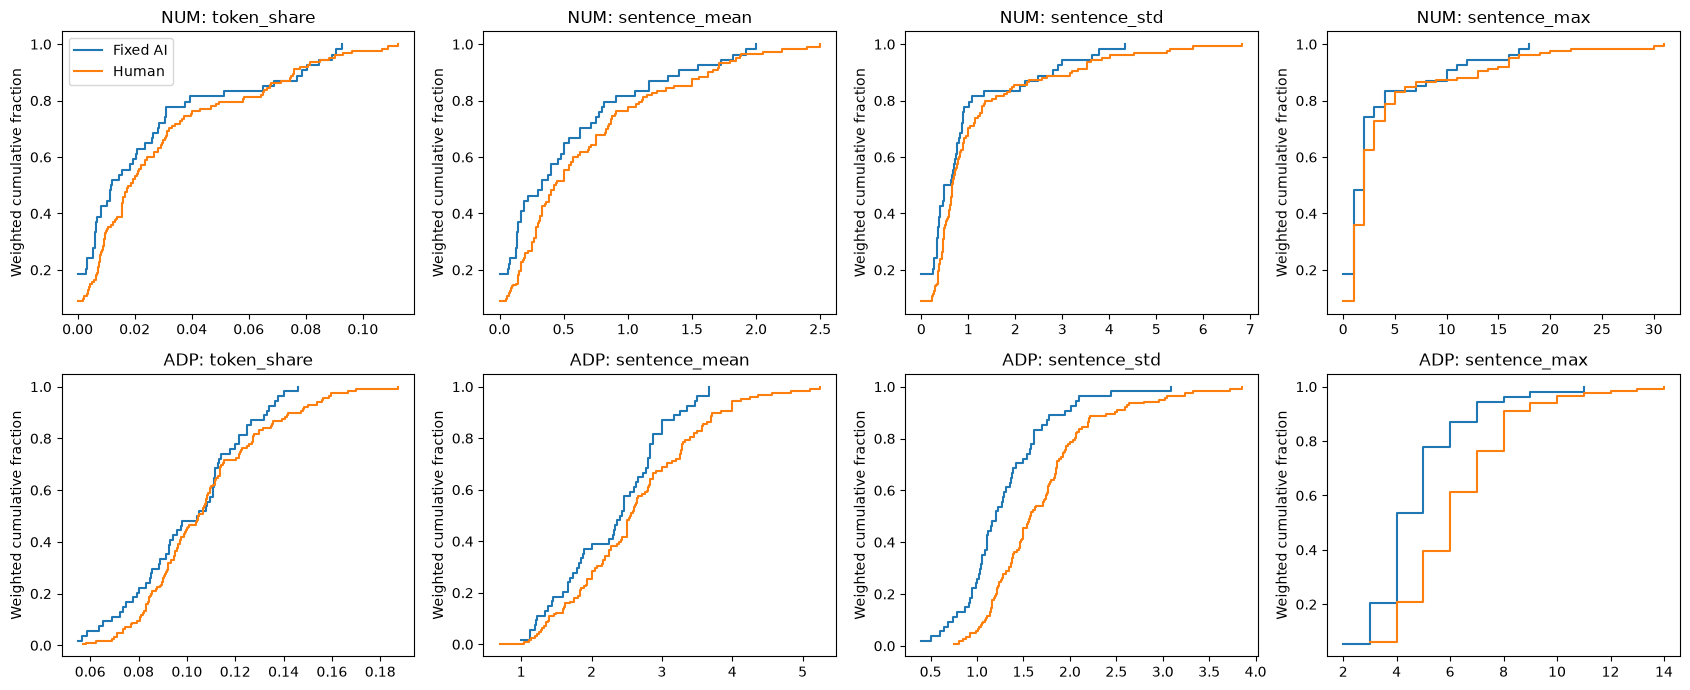

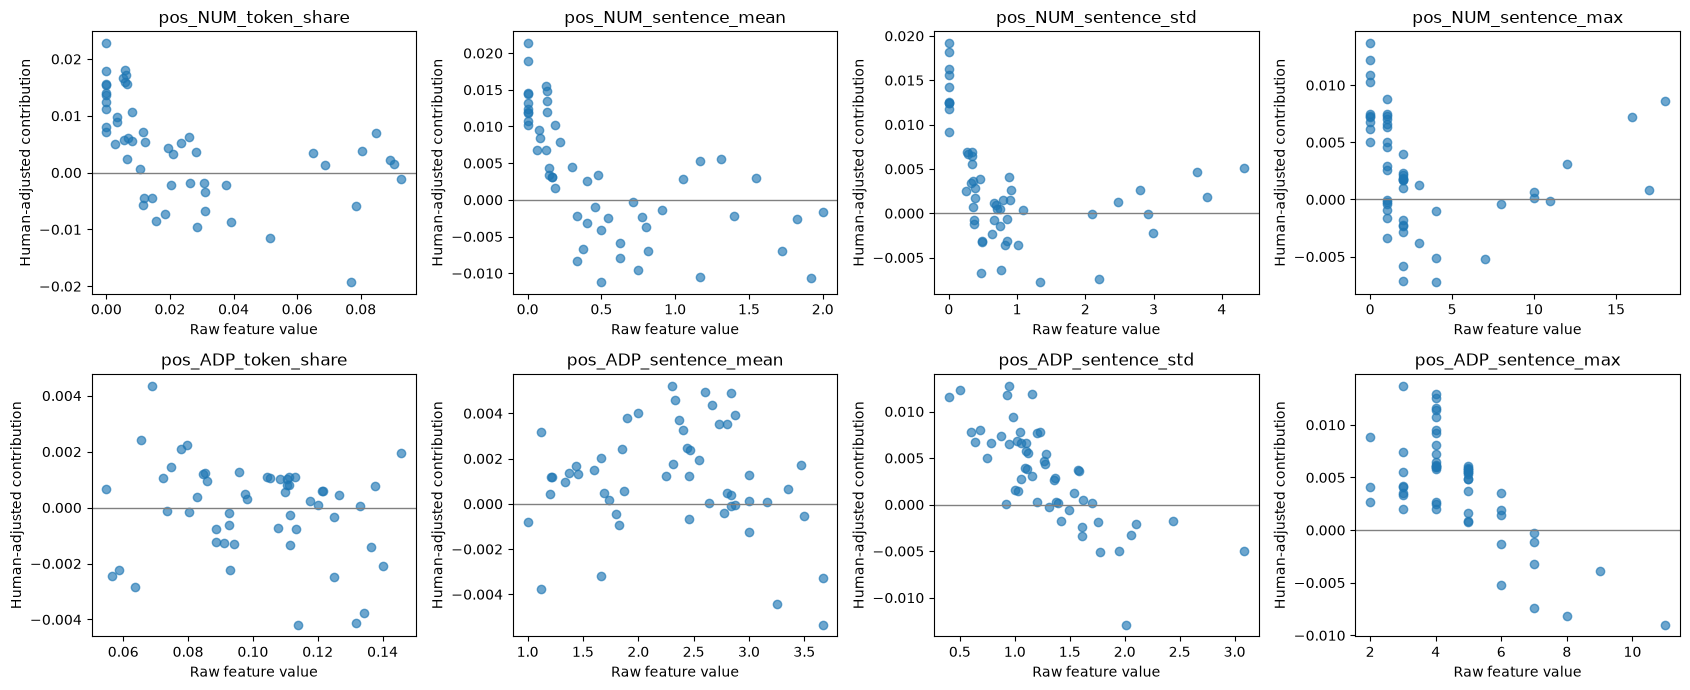

Saved: ../results/causal/C03d_NUM_ADP_audit/49652897a361


In [4]:
# C03d — ADV / NUM / ADP audit on post-5.5 texts.
TAGS = ["NUM", "ADP"]
STATS = ["token_share", "sentence_mean", "sentence_std", "sentence_max"]


human_manifest = pd.read_csv(RUN_DIR / "human_test_manifest.csv")
mix = data.domain.value_counts(normalize=True)

specs = [
    dict(group="Fixed AI", case_id=r.case_id, source_id=r.source_id,
         domain=r.domain, text=r.text)
    for r in final_eval.itertuples()
] + [
    dict(group="Human", case_id=str(r.source_id), source_id=r.source_id,
         domain=r.domain, text=text_map55[r.source_id])
    for r in human_manifest.itertuples()
]

document_rows, sentence_rows, token_rows = [], [], []

for spec, doc in zip(
    specs,
    nlp.pipe([normalize(s["text"]) for s in specs], batch_size=32),
):
    meta = {k: spec[k] for k in ("group", "case_id", "source_id", "domain")}
    sentences = [
        s for s in doc.sents if any(not t.is_space for t in s)
    ]
    tokens = [t for t in doc if not t.is_space]

    for tag in TAGS:
        counts = np.array([
            sum(t.pos_ == tag for t in s if not t.is_space)
            for s in sentences
        ], dtype=float)

        document_rows.append({
            **meta, "tag": tag,
            "n_tokens": len(tokens),
            "n_sentences": len(sentences),
            "tokens_per_sentence": len(tokens) / max(1, len(sentences)),
            "token_share": sum(t.pos_ == tag for t in tokens)
                           / max(1, len(tokens)),
            "sentence_mean": counts.mean() if len(counts) else 0.,
            "sentence_std": counts.std() if len(counts) else 0.,
            "sentence_max": counts.max() if len(counts) else 0.,
        })

        for j, sent in enumerate(sentences):
            selected = [t for t in sent if t.pos_ == tag]
            sent_length = sum(not t.is_space for t in sent)

            # Mark occurrences using offsets, preserving the actual sentence.
            marked = sent.text
            for t in reversed(selected):
                a = t.idx - sent.start_char
                b = a + len(t.text)
                marked = marked[:a] + "⟦" + marked[a:b] + "⟧" + marked[b:]

            sentence_rows.append({
                **meta, "tag": tag, "sentence_index": j,
                "count": len(selected), "sentence_tokens": sent_length,
                "share": len(selected) / max(1, sent_length),
                "sentence": sent.text, "highlighted": marked,
            })

            for t in selected:
                # Structural description, not an automatic semantic judgment.
                prefix = doc.text[max(0, t.idx - 20):t.idx]
                role = t.dep_
                if tag == "NUM" and re.search(r"\bstep\s*$", prefix, re.I):
                    role = "step_label_candidate"

                token_rows.append({
                    **meta, "tag": tag,
                    "token": t.text, "lemma": t.lemma_.lower(),
                    "fine_tag": t.tag_, "dependency": t.dep_,
                    "role": role, "head": t.head.text,
                    "head_pos": t.head.pos_,
                    "sentence_index": j,
                    "sentence": sent.text,
                })

doc_audit = pd.DataFrame(document_rows)
sent_audit = pd.DataFrame(sentence_rows)
tok_audit = pd.DataFrame(token_rows)

doc_audit.to_csv(audit_dir / "document_statistics.csv", index=False)
sent_audit.to_csv(audit_dir / "sentence_contexts.csv", index=False)
tok_audit.to_csv(audit_dir / "token_contexts.csv", index=False)

# Confirm that the audit reproduces the detector's feature definitions.
for tag in TAGS:
    subset = doc_audit.loc[
        doc_audit.group.eq("Fixed AI") & doc_audit.tag.eq(tag)
    ].set_index("case_id").loc[final_eval.case_id]
    for stat in STATS:
        np.testing.assert_allclose(
            subset[stat].to_numpy(),
            X_final[f"pos_{tag}_{stat}"].to_numpy(),
            atol=1e-10, rtol=0,
        )

# Human comparisons use the same genre mixture as the 54 AI texts.
summary_rows = []
for (group, genre, tag), subset in doc_audit.groupby(
    ["group", "domain", "tag"]
):
    for stat in STATS:
        summary_rows.append({
            "group": group, "domain": genre, "tag": tag,
            "statistic": stat, "documents": len(subset),
            "mean": subset[stat].mean(),
            "median": subset[stat].median(),
            "q10": subset[stat].quantile(.10),
            "q90": subset[stat].quantile(.90),
        })

genre_summary = pd.DataFrame(summary_rows)
genre_summary.to_csv(audit_dir / "statistics_by_genre.csv", index=False)

weighted_rows = []
for (group, tag, stat), subset in genre_summary.groupby(
    ["group", "tag", "statistic"]
):
    assert set(mix.index) <= set(subset.domain)
    weighted_rows.append({
        "group": group, "tag": tag, "statistic": stat,
        "weighted_mean": np.sum(subset.domain.map(mix) * subset["mean"]),
    })

weighted_summary = pd.DataFrame(weighted_rows)
weighted_summary.to_csv(audit_dir / "weighted_statistics.csv", index=False)
display(weighted_summary.pivot(
    index=["tag", "statistic"], columns="group", values="weighted_mean"
))

# Frequent lemmas and grammatical roles.
# Count per document first, so zero-occurrence documents enter denominators.
def frequency_table(key):
    counts = tok_audit.groupby(
        ["group", "domain", "tag", "case_id", key]
    ).size().rename("count").reset_index()

    denominators = doc_audit[
        ["group", "domain", "tag", "case_id", "n_tokens"]
    ]
    counts = counts.merge(
        denominators,
        on=["group", "domain", "tag", "case_id"],
        validate="many_to_one",
    )
    counts["per_1000"] = 1000 * counts["count"] / counts.n_tokens

    totals = doc_audit.groupby(
        ["group", "domain", "tag"]
    ).size().rename("n_documents")

    by_genre = counts.groupby(
        ["group", "domain", "tag", key]
    ).agg(
        token_count=("count", "sum"),
        documents_with=("case_id", "nunique"),
        rate_sum=("per_1000", "sum"),
    ).reset_index().merge(
        totals.reset_index(), on=["group", "domain", "tag"]
    )
    by_genre["weighted_rate"] = (
        by_genre.rate_sum / by_genre.n_documents
        * by_genre.domain.map(mix)
    )
    by_genre["weighted_prevalence"] = (
        by_genre.documents_with / by_genre.n_documents
        * by_genre.domain.map(mix)
    )

    result = by_genre.groupby(["group", "tag", key]).agg(
        token_count=("token_count", "sum"),
        documents_with=("documents_with", "sum"),
        weighted_per_1000=("weighted_rate", "sum"),
        weighted_prevalence=("weighted_prevalence", "sum"),
    ).reset_index()
    return result

for key in ["lemma", "role"]:
    frequencies = frequency_table(key)
    frequencies.to_csv(audit_dir / f"{key}_frequencies.csv", index=False)
    for tag in TAGS:
        print(f"\n{tag}: {key}")
        comparison = frequencies.loc[frequencies.tag.eq(tag)].pivot(
            index=key, columns="group", values="weighted_per_1000"
        ).fillna(0)
        comparison["AI_minus_human"] = (
            comparison["Fixed AI"] - comparison["Human"]
        )
        display(comparison.sort_values(
            "AI_minus_human", ascending=False
        ).head(20))
        print("Most human-enriched:")
        display(comparison.sort_values("AI_minus_human").head(10))

# Print one maximum-count sentence per document, including its length.
# Full sentence/context tables are saved above.
for tag in TAGS:
    for group in ["Fixed AI", "Human"]:
        subset = sent_audit.loc[
            sent_audit.tag.eq(tag) & sent_audit.group.eq(group)
        ]
        peaks = (
            subset.sort_values(
                ["count", "sentence_tokens"], ascending=False
            )
            .drop_duplicates("case_id")
            .head(10)
        )
        print(f"\n{group} — {tag}: highest-count sentences")
        for r in peaks.itertuples():
            print(
                f"{r.case_id} [{r.domain}] "
                f"{r.count} {tag} / {r.sentence_tokens} tokens\n"
                f"{r.highlighted}\n"
            )

# Plots: raw distributions and raw values versus document contributions.
# Contributions are document-level, not token-level attributions.
gap_df = pd.DataFrame(
    final_gap, columns=COLS, index=final_eval.case_id
)

def save_pos_audit(fig, stem):
    fig.tight_layout()
    for folder in (audit_dir, FIG):
        for ext in ("pdf", "png"):
            fig.savefig(
                folder / f"C03d_post_ADV_{stem}.{ext}",
                dpi=300, bbox_inches="tight",
            )
    plt.show()

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for i, tag in enumerate(TAGS):
    for j, stat in enumerate(STATS):
        ax = axes[i, j]
        for group in ["Fixed AI", "Human"]:
            subset = doc_audit.loc[
                doc_audit.tag.eq(tag) & doc_audit.group.eq(group)
            ].copy()
            counts = subset.domain.value_counts()
            subset["weight"] = [
                mix[g] / counts[g] for g in subset.domain
            ]
            # Aggregate ties for a proper empirical CDF.
            curve = subset.groupby(stat).weight.sum().sort_index().cumsum()
            ax.step(curve.index, curve.values, where="post", label=group)
        ax.set(title=f"{tag}: {stat}", ylabel="Weighted cumulative fraction")
axes[0, 0].legend()
save_pos_audit(fig, "POS_distributions")

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
association_rows = []
for i, tag in enumerate(TAGS):
    subset = doc_audit.loc[
        doc_audit.tag.eq(tag) & doc_audit.group.eq("Fixed AI")
    ].set_index("case_id").loc[final_eval.case_id]
    for j, stat in enumerate(STATS):
        feature = f"pos_{tag}_{stat}"
        x = subset[stat].to_numpy()
        y = gap_df[feature].to_numpy()
        ax = axes[i, j]
        ax.scatter(x, y, alpha=.65)
        ax.axhline(0, color="gray", linewidth=1)
        ax.set(title=feature, xlabel="Raw feature value",
               ylabel="Human-adjusted contribution")
        association_rows.extend({
            "case_id": cid, "feature": feature,
            "raw_value": a, "contribution_gap": b,
        } for cid, a, b in zip(final_eval.case_id, x, y))

pd.DataFrame(association_rows).to_csv(
    audit_dir / "values_and_contributions.csv", index=False
)
save_pos_audit(fig, "POS_values_vs_contributions")

print("Saved:", audit_dir)

,feature,raw_mean_contribution,before_gap,human_adjusted_gap,ci_low,ci_high,contribution_change,change_ci_low,change_ci_high,fraction_AI_directed
0,pos_NUM_token_share,0.000726,0.004173,0.004195,0.001885,0.006400,0.000022,-0.000130,0.000167,0.685185
1,pos_ADP_sentence_max,0.001970,0.004130,0.004079,0.002798,0.005289,-0.000051,-0.000202,0.000085,0.833333
2,pos_NUM_sentence_mean,0.000194,0.003286,0.003262,0.001220,0.005359,-0.000024,-0.000143,0.000099,0.592593
3,pos_ADP_sentence_std,0.001440,0.003148,0.003216,0.001951,0.004430,0.000068,-0.000101,0.000263,0.759259
5,pos_NUM_sentence_std,0.000428,0.003187,0.003099,0.001597,0.004743,-0.000088,-0.000206,0.000025,0.666667
10,pos_NUM_sentence_max,0.000705,0.002552,0.002450,0.001296,0.003629,-0.000102,-0.000213,-0.000010,0.648148
37,pos_ADP_sentence_mean,0.000693,0.001059,0.001091,0.000577,0.001584,0.000032,-0.000108,0.000169,0.740741
150,pos_ADP_token_share,-0.000165,0.000059,-0.000065,-0.000488,0.000351,-0.000124,-0.000229,-0.000024,0.574074


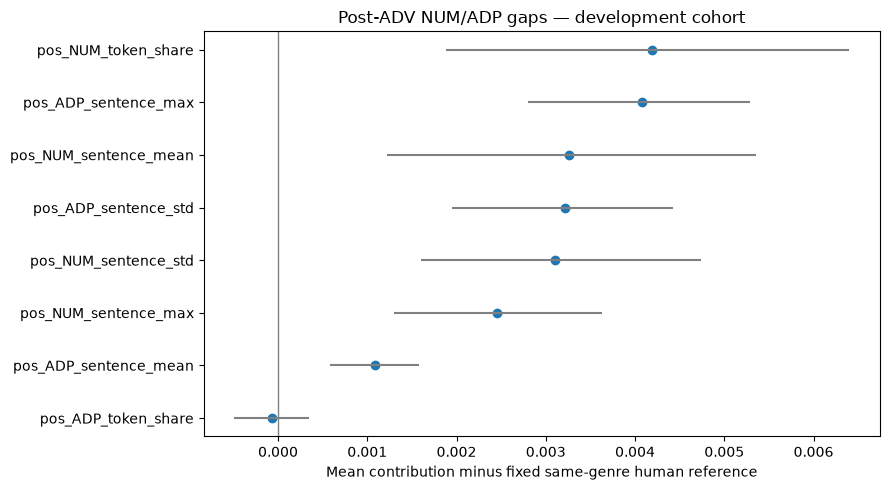

Audit complete. No NUM/ADP edits applied.
Use raw direction, genre concentration, and contextual roles to specify deterministic candidates next.


In [5]:
ranking=pd.read_csv(ACCEPTED_DIR/'remaining_contributions.csv')
target=ranking.loc[ranking.feature.str.match(r'^pos_(NUM|ADP)_')].copy()
target.to_csv(audit_dir/'NUM_ADP_remaining_contributions.csv',index=False)
display(target)
target=target.sort_values('human_adjusted_gap')
fig,ax=plt.subplots(figsize=(9,5));y=np.arange(len(target))
ax.hlines(y,target.ci_low,target.ci_high,color='gray')
ax.scatter(target.human_adjusted_gap,y)
ax.set_yticks(y,target.feature);ax.axvline(0,color='gray',lw=1)
ax.set_xlabel('Mean contribution minus fixed same-genre human reference')
ax.set_title('Post-ADV NUM/ADP gaps — development cohort')
save_pos_audit(fig,'NUM_ADP_remaining_contributions')
print('Audit complete. No NUM/ADP edits applied.')
print('Use raw direction, genre concentration, and contextual roles to specify deterministic candidates next.')


## Next: deterministic operator design

A positive contribution gap alone does not specify whether counts should rise or fall. Use the audit to identify the direction and structural sources first. Preserve numeric values, units, named entities, and factual relationships. Assess candidates through full-document retagging, contextual likelihood with both preceding and following context, and frozen detector contributions, with collateral effects recorded separately.

No prior intervention or detector training is rerun. If the accepted evaluation directory is missing, point the loader at the original saved artifacts; do not substitute pre-ADV texts.

The plots export PDF and PNG to both the run directory and `ROOT / 'figures'`. These are descriptive development-cohort diagnostics, not evidence of a NUM/ADP treatment effect.


## ADP boost and compensation — bounded deterministic pilot

If the audit already ran in this kernel, run only the cells below. Save this updated notebook at its normal path before running so its code hash matches the file.

The threshold is the ceiling of the fixed same-genre human median ADP sentence maximum (minimum 1). Sentences already at or above it are protected. A sentence below it is a candidate maximum when the bounded search finds a likelihood-admissible path to the threshold. The third category records no reachable boost within the tested inventory and bounds; this does not prove impossibility.

This first pilot boosts at most one new high-count sentence per document. It searches up to three edits per sentence with beam width two and scores at most forty mechanically admissible candidates per state. Up to eight subsequent reductions in below-threshold sentences attempt to restore the original token share. Actual ratios, maxima and population SD are recomputed. Compensation is best-effort; a residual share difference is reported rather than hidden.

Candidates combine stored-direction PPDB Equivalence pairs with a small adjacent-noun compound expansion/contraction family inspired by Nakov (ECAI 2008). This is an adaptation, not an exact reproduction: the scorer replaces live web-hit evidence, and the restricted patterns omit much of the original system. PPDB is scanned for baseline phrases only, including both increasing and decreasing alternatives; later edits do not trigger additional resource scans. Broad and local contextual likelihood differences must each be at least −1.0 nats/token. These permissive checks do not guarantee semantic equivalence.

Names/entities, numeric token sequences, explicit dependency negation, punctuation, sentence count and every unedited sentence are protected. The final combined operation must improve the ADP contribution block, avoid increasing combined non-ADP contributions, preserve or raise the document maximum, and strictly increase SD. Individual other coordinates may still increase. All 54 documents remain in evaluation.

Each run records targets, resource/input/code identity, candidate budgets, trial scores, and per-case checkpoints. A changed scientific contract creates a new run. CPU/GPU identity and versions are recorded; deterministic execution is conditional on that runtime. Long-running cells print progress; no completion estimate is assumed.

Reference: [Nakov, Improved Statistical Machine Translation Using Monolingual Paraphrases](https://arxiv.org/abs/2109.15119).


In [6]:
# C03d ADP controller — run after the audit cells. No NUM edits.
import gzip, math, time, platform
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

ADP_CFG = dict(version='boost_compensate_v1', target='ceil_same_genre_human_median_sentence_max',
    beam_width=2, max_boost_edits=3, candidates_per_state=40, max_compensation_edits=8,
    context_words=48, local_following_tokens=8, likelihood_floor=-1.0,
    max_phrase_words=8, seed=20260909)
PPDB_PATH = ROOT/'external/ppdb/ppdb-2.0-l-all.gz'
assert PPDB_PATH.is_file(), f'Use the pinned C03c PPDB file at {PPDB_PATH}; no new download is needed.'
def adp_hash(obj):
    return hashlib.sha256(json.dumps(obj,sort_keys=True,ensure_ascii=False).encode()).hexdigest()
def adp_atomic(path,obj):
    temp=path.with_suffix('.tmp');temp.write_text(json.dumps(obj,ensure_ascii=False,indent=2));temp.replace(path)
def adp_filehash(p):
    h=hashlib.sha256()
    with p.open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''): h.update(block)
    return h.hexdigest()
print('Checking pinned PPDB bytes...',flush=True)
assert adp_filehash(PPDB_PATH)=='0fde517b55fcaa08a87534df78236d8803c9e8c00382415f5f15ae51ecf3330e'
adp_treatment=json.loads((ROOT/'results/causal/C02r_discovery_gated_punctuation/treatment_contract.json').read_text())
assert re.fullmatch('[0-9a-fA-F]{40}',adp_treatment['scorer_revision'])
torch.manual_seed(ADP_CFG['seed'])
torch.use_deterministic_algorithms(True)
adp_device='cuda' if torch.cuda.is_available() else 'cpu' # Bound into the run contract.
adp_nb=json.loads((ROOT/'experiments/C03d_NUM_ADP_audit.ipynb').read_text())
adp_contract=dict(config=ADP_CFG, parent_audit=record, text_hash=adp_hash(final_eval.text.tolist()),
    scorer=adp_treatment['scorer'],revision=adp_treatment['scorer_revision'],device=adp_device,
    torch=torch.__version__,numpy=np.__version__,python=platform.python_version(),
    code=adp_hash([c['source'] for c in adp_nb['cells'] if c['cell_type']=='code']))
adp_dir=ROOT/'results/causal/C03d_ADP_boost_compensate'/adp_hash(adp_contract)[:12]
adp_dir.mkdir(parents=True,exist_ok=True)
if (adp_dir/'contract.json').exists(): assert json.loads((adp_dir/'contract.json').read_text())==adp_contract
else: adp_atomic(adp_dir/'contract.json',adp_contract)
for sub in ['cases','vectors','likelihood','trials']: (adp_dir/sub).mkdir(exist_ok=True)
ADP_IX=[i for i,c in enumerate(COLS) if c.startswith('pos_ADP_')]
OTHER_IX=[i for i in range(186) if i not in ADP_IX]

# Freeze targets BEFORE search; use the same human documents as the audit.
adp_targets={g:max(1,int(math.ceil(doc_audit.loc[(doc_audit.group=='Human') &
    (doc_audit.domain==g) & (doc_audit.tag=='ADP'),'sentence_max'].median())))
    for g in sorted(final_eval.domain.unique())}
adp_atomic(adp_dir/'targets.json',adp_targets)
display(pd.DataFrame([dict(domain=g,target=t) for g,t in adp_targets.items()]))

@lru_cache(maxsize=1024)
def adp_doc(text): return nlp(text)
def adp_sents(doc): return [s for s in doc.sents if any(not t.is_space for t in s)]
def adp_counts(doc): return [sum(t.pos_=='ADP' for t in s) for s in adp_sents(doc)]
def adp_signature(doc):
    return ([t.text for t in doc if t.pos_ in {'NUM','PROPN'}],
            [t.text.lower() for t in doc if t.dep_=='neg'],
            [t.text for t in doc if t.is_punct],
            [(e.text,e.label_) for e in doc.ents])
def adp_spans(doc):
    for si,s in enumerate(adp_sents(doc)):
        ts=list(s)
        for i,t in enumerate(ts):
            if not t.is_alpha: continue
            for j in range(i,min(len(ts),i+ADP_CFG['max_phrase_words'])):
                if not ts[j].is_alpha: break
                if any(u.pos_ in {'NUM','PROPN'} or u.ent_type_ for u in ts[i:j+1]): continue
                yield si,t.idx,ts[j].idx+len(ts[j]),doc.text[t.idx:ts[j].idx+len(ts[j])]

# Scan PPDB once for phrases observed in the accepted baseline, including reductions.
# Later states may reuse these rules; newly introduced source phrases are not rescanned.
ppfile=adp_dir/'ppdb_pairs.json'
if ppfile.exists(): adp_pairs=json.loads(ppfile.read_text())
else:
    observed={' '.join(phrase.lower().split()) for text in final_eval.text for _,_,_,phrase in adp_spans(adp_doc(normalize(text)))}
    pairs={};started=time.monotonic()
    with gzip.open(PPDB_PATH,'rt',encoding='utf-8') as f:
        for n,line in enumerate(f,1):
            if n%1000000==0: print(f'PPDB: {n:,} rows, {time.monotonic()-started:.0f}s',flush=True)
            fields=[v.strip() for v in line.split('|||')]
            if len(fields)<6: continue
            src,dst=(' '.join(v.lower().split()) for v in fields[1:3])
            if fields[-1].strip()!='Equivalence' or src not in observed or src==dst: continue
            if not (1<=len(dst.split())<=8) or not all(w.isalpha() for w in dst.split()): continue
            pairs.setdefault(src,set()).add(dst)
    adp_pairs={k:sorted(v) for k,v in sorted(pairs.items())}
    adp_atomic(ppfile,adp_pairs)
print('PPDB source phrases:',len(adp_pairs),'Output:',adp_dir,flush=True)



/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Checking pinned PPDB bytes...


,domain,target
0,abstracts,6
1,books,7
2,news,6
3,recipes,5
4,reddit,5
5,reviews,6
6,wiki,8


PPDB: 1,000,000 rows, 3s
PPDB: 2,000,000 rows, 7s
PPDB: 3,000,000 rows, 11s
PPDB: 4,000,000 rows, 14s
PPDB: 5,000,000 rows, 18s
PPDB: 6,000,000 rows, 22s
PPDB: 7,000,000 rows, 25s
PPDB: 8,000,000 rows, 29s
PPDB: 9,000,000 rows, 33s
PPDB: 10,000,000 rows, 36s
PPDB: 11,000,000 rows, 40s
PPDB: 12,000,000 rows, 44s
PPDB: 13,000,000 rows, 48s
PPDB: 14,000,000 rows, 52s
PPDB: 15,000,000 rows, 55s
PPDB: 16,000,000 rows, 59s
PPDB: 17,000,000 rows, 63s
PPDB: 18,000,000 rows, 66s
PPDB source phrases: 3201 Output: ../results/causal/C03d_ADP_boost_compensate/1d921b4b832b


In [7]:
# A small fixed syntactic proposal family inspired by Nakov (ECAI 2008).
# These are proposals, never assumed semantic equivalences.
def adp_candidates(text,allowed,direction):
    doc=adp_doc(text);sents=adp_sents(doc);before=adp_counts(doc);sig=adp_signature(doc)
    proposals=set()
    for si,a,b,phrase in adp_spans(doc):
        if si not in allowed: continue
        for repl in adp_pairs.get(' '.join(phrase.lower().split()),[]):
            if phrase[0].isupper(): repl=repl[0].upper()+repl[1:]
            proposals.add((si,a,b,repl,'PPDB'))
    for si,s in enumerate(sents):
        if si not in allowed: continue
        ts=list(s)
        for i,t in enumerate(ts[:-1]):
            h=ts[i+1]
            if direction>0 and t.pos_=='NOUN' and h.pos_=='NOUN' and t.dep_=='compound' and t.head==h:
                # Avoid sentence-initial case adjustment, modifiers and named entities.
                if t.i==s.start or list(t.children) or t.ent_type_ or h.ent_type_: continue
                for prep in ['about','at','for','from','in','of','on','with']:
                    proposals.add((si,t.idx,h.idx+len(h),h.text+' '+prep+' '+t.text,'compound_expand'))
            if direction<0 and i+2<len(ts):
                p,u=ts[i+1:i+3]
                if t.pos_=='NOUN' and p.pos_=='ADP' and u.pos_=='NOUN' and p.head==t and u.head==p:
                    if t.i==s.start or list(u.children) or t.ent_type_ or u.ent_type_: continue
                    proposals.add((si,t.idx,u.idx+len(u),u.text+' '+t.text,'compound_contract'))
    # Stable budget, PPDB first. Report search bounds in the contract and case status.
    proposals=sorted(proposals,key=lambda r:(r[4]!='PPDB',r[0],r[1],r[2],r[3]))
    survivors=[]
    for si,a,b,repl,kind in proposals:
        edited=text[:a]+repl+text[b:];new=adp_doc(edited);ns=adp_sents(new)
        if len(ns)!=len(sents) or adp_signature(new)!=sig: continue
        # Preserve every other sentence verbatim (also protects sentence boundaries).
        if any(ns[j].text!=sents[j].text for j in range(len(ns)) if j!=si): continue
        counts=adp_counts(new)
        if direction*(counts[si]-before[si])<=0: continue
        if any(counts[j]!=before[j] for j in range(len(ns)) if j!=si): continue
        survivors.append(dict(text=edited,si=si,a=a,b=b,repl=repl,kind=kind,counts=counts))
    return survivors

adp_tok=AutoTokenizer.from_pretrained(adp_treatment['scorer'],revision=adp_treatment['scorer_revision'],use_fast=True)
assert adp_tok.is_fast
adp_model=AutoModelForCausalLM.from_pretrained(adp_treatment['scorer'],revision=adp_treatment['scorer_revision']).to(adp_device).eval()
adp_limit=getattr(adp_model.config,'max_position_embeddings',1024)
def adp_ll(left,span,right,local):
    enc=adp_tok(left+span+right,add_special_tokens=False,return_offsets_mapping=True)
    ids=enc['input_ids'];offs=enc['offset_mapping'];boundary=len(left)+len(span)
    following=[i for i,(a,b) in enumerate(offs) if a>=boundary][:8]
    mask=[b>len(left) and (not local or a<boundary or i in following) for i,(a,b) in enumerate(offs)]
    if not any(mask): return None
    last=max(i for i,v in enumerate(mask) if v)+1;ids=ids[:last];mask=mask[:last]
    if not left:
        ids=[adp_tok.bos_token_id or adp_tok.eos_token_id]+ids;mask=[False]+mask
    if len(ids)>adp_limit: return None
    p=adp_dir/'likelihood'/(adp_hash([ids,mask])+'.json')
    if p.exists(): return json.loads(p.read_text())['value']
    with torch.inference_mode():
        x=torch.tensor([ids],device=adp_device)
        logits=adp_model(x,use_cache=False).logits[:,:-1]
        loss=torch.nn.functional.cross_entropy(logits.reshape(-1,logits.shape[-1]),x[:,1:].reshape(-1),reduction='none')
        m=torch.tensor(mask[1:],device=adp_device,dtype=torch.bool)
        if not m.any(): return None
        value=-float(loss[m].mean().cpu())
    adp_atomic(p,dict(value=value));return value

def adp_gate(old,candidate):
    a,b=candidate['a'],candidate['b'];prefix,suffix=old[:a],old[b:]
    l=list(re.finditer(r'\S+',prefix));r=list(re.finditer(r'\S+',suffix))
    left=prefix[l[-48].start():] if len(l)>48 else prefix
    right=suffix[:r[47].end()] if len(r)>48 else suffix
    deltas=[]
    for local in [False,True]:
        x=adp_ll(left,old[a:b],right,local);y=adp_ll(left,candidate['repl'],right,local)
        if x is None or y is None: return None
        deltas.append(y-x)
    return deltas if min(deltas)>=ADP_CFG['likelihood_floor'] else None

def adp_vector(text):
    p=adp_dir/'vectors'/(adp_hash(text)+'.npz')
    if p.exists():
        with np.load(p,allow_pickle=False) as f: return f['x'],f['c']
    x=full_frame([text]);c=contributions(x)[0];v=x.iloc[0].to_numpy()
    temp=p.with_suffix('.tmp')
    with temp.open('wb') as f: np.savez_compressed(f,x=v,c=c)
    temp.replace(p);return v,c

def adp_measure(text):
    x,c=adp_vector(text)
    return dict(max=float(x[COLS.index('pos_ADP_sentence_max')]),sd=float(x[COLS.index('pos_ADP_sentence_std')]),
        share=float(x[COLS.index('pos_ADP_token_share')]),adp=float(c[ADP_IX].sum()),other=float(c[OTHER_IX].sum()))



Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████| 148/148 [00:00<00:00, 13337.28it/s]


In [8]:
# Bounded beam search within ONE sentence; completed cases resume without repeating search.
# 'No reachable boost' means under the recorded candidate inventory and search bounds.
def adp_process(row):
    original=normalize(row.text);base=adp_measure(original);target=adp_targets[row.domain]
    initial=adp_counts(adp_doc(original));protected={i for i,a in enumerate(initial) if a>=target}
    trials=[];search_log=[];categories=[dict(sentence=i,initial_count=a,threshold=target,
        category='already_high' if i in protected else 'no_reachable_boost_within_bounds') for i,a in enumerate(initial)]
    completed=[]
    def evaluate(old,proposal,phase,depth):
        ident=adp_hash([old,proposal['text']]);p=adp_dir/'trials'/(ident+'.json')
        if p.exists(): outcome=json.loads(p.read_text())
        else:
            gates=adp_gate(old,proposal)
            outcome=dict(likelihood_pass=gates is not None,deltas=gates)
            if gates is not None: outcome['metrics']=adp_measure(proposal['text'])
            adp_atomic(p,outcome)
        trials.append(dict(case_id=row.case_id,phase=phase,depth=depth,sentence=proposal['si'],
            candidate_id=ident,kind=proposal['kind'],source=old[proposal['a']:proposal['b']],
            replacement=proposal['repl'],**outcome))
        return outcome
    for si in range(len(initial)):
        if si in protected: continue
        beam=[dict(text=original,edits=[])];seen={original}
        for depth in range(1,ADP_CFG['max_boost_edits']+1):
            next_states=[]
            for state in beam:
                proposals=adp_candidates(state['text'],{si},1)
                search_log.append(dict(phase='boost',sentence=si,depth=depth,admissible_before_likelihood=len(proposals),evaluated_cap=ADP_CFG['candidates_per_state']))
                # Favor reaching the threshold, then smaller overshoot / stable enumeration.
                proposals.sort(key=lambda p:(abs(target-p['counts'][si]),p['a'],p['b'],p['repl']))
                for proposal in proposals[:ADP_CFG['candidates_per_state']]:
                    if proposal['text'] in seen: continue
                    seen.add(proposal['text'])
                    outcome=evaluate(state['text'],proposal,'boost',depth)
                    if not outcome['likelihood_pass']: continue
                    metrics=outcome['metrics']
                    nxt=dict(text=proposal['text'],edits=state['edits']+[dict(sentence=si,
                        source=state['text'][proposal['a']:proposal['b']],replacement=proposal['repl'],
                        kind=proposal['kind'],deltas=outcome['deltas'])],metrics=metrics)
                    if proposal['counts'][si]>=target:
                        categories[si]['category']='candidate_max_reachable'
                        completed.append(nxt)
                    else: next_states.append(nxt)
            next_states.sort(key=lambda st:(-adp_counts(adp_doc(st['text']))[si],st['metrics']['adp'],adp_hash(st['text'])))
            beam=next_states[:ADP_CFG['beam_width']]
            if not beam: break
        print(f'{row.case_id}: sentence {si+1}/{len(initial)}, {len(trials)} scored candidates',flush=True)
    # Keep a bounded set of attained boosts to attempt compensation.
    completed.sort(key=lambda st:(st['metrics']['adp'],abs(st['metrics']['share']-base['share']),adp_hash(st['text'])))
    finalists=[]
    for boost in completed[:ADP_CFG['beam_width']]:
        current=boost['text'];edits=list(boost['edits']);metrics=boost['metrics'];comp_edits=[]
        locked={i for i,a in enumerate(adp_counts(adp_doc(current))) if a>=target}
        # The boost itself can be accepted when compensation offers no admissible improvement.
        for step in range(ADP_CFG['max_compensation_edits']):
            allowed=set(range(len(initial)))-locked
            proposals=adp_candidates(current,allowed,-1)
            search_log.append(dict(phase='compensate',depth=step+1,admissible_before_likelihood=len(proposals),evaluated_cap=ADP_CFG['candidates_per_state']))
            # Prefer reductions in low-count sentences; likelihood and actual ratio decide acceptance.
            proposals.sort(key=lambda p:(adp_counts(adp_doc(current))[p['si']],p['si'],p['a'],p['repl']))
            options=[]
            for proposal in proposals[:ADP_CFG['candidates_per_state']]:
                outcome=evaluate(current,proposal,'compensate',step+1)
                if not outcome['likelihood_pass']: continue
                m=outcome['metrics']
                if m['max']!=boost['metrics']['max']: continue
                if abs(m['share']-base['share'])>=abs(metrics['share']-base['share'])-1e-12: continue
                if m['sd']<base['sd']-1e-12: continue
                options.append((abs(m['share']-base['share']),m['adp'],adp_hash(proposal['text']),proposal,m,outcome))
            if not options: break
            _,_,_,p,m,o=min(options,key=lambda z:z[:3])
            comp_edits.append(dict(sentence=p['si'],source=current[p['a']:p['b']],replacement=p['repl'],kind=p['kind'],deltas=o['deltas']))
            current=p['text'];metrics=m
        # Combined operation acceptance; intermediate edits need not pass contribution constraints.
        accepted=(metrics['adp']<base['adp']-1e-12 and metrics['other']<=base['other']+1e-12
                  and metrics['max']>=base['max'] and metrics['sd']>base['sd']+1e-12)
        if accepted:
            finalists.append(dict(text=current,metrics=metrics,boost_edits=edits,compensation_edits=comp_edits,
                boost_metrics=boost['metrics'],compensation_status='improved' if comp_edits else 'no_admissible_reduction'))
    finalists.sort(key=lambda x:(x['metrics']['adp'],abs(x['metrics']['share']-base['share']),adp_hash(x['text'])))
    selected=finalists[0] if finalists else dict(text=original,metrics=base,boost_edits=[],compensation_edits=[])
    # Final lock check independent of the generation logic.
    final_sents=adp_sents(adp_doc(selected['text']));orig_sents=adp_sents(adp_doc(original))
    assert len(final_sents)==len(orig_sents)
    assert all(final_sents[i].text==orig_sents[i].text for i in protected)
    return dict(case_id=row.case_id,source_id=row.source_id,domain=row.domain,target=target,
        status='accepted' if finalists else ('no_final_acceptance' if completed else 'no_reachable_boost_within_bounds'),
        baseline=base,categories=categories,trials=trials,search_log=search_log,**selected)



Starting gate_0001
gate_0001: sentence 2/6, 55 scored candidates
gate_0001: sentence 3/6, 126 scored candidates
gate_0001: sentence 4/6, 155 scored candidates
gate_0001: sentence 5/6, 163 scored candidates
gate_0001: sentence 6/6, 269 scored candidates
Completed 1/54: gate_0001 — accepted
Starting gate_0003
gate_0003: sentence 1/19, 8 scored candidates
gate_0003: sentence 2/19, 33 scored candidates
gate_0003: sentence 3/19, 124 scored candidates
gate_0003: sentence 4/19, 124 scored candidates
gate_0003: sentence 5/19, 151 scored candidates
gate_0003: sentence 6/19, 151 scored candidates
gate_0003: sentence 7/19, 151 scored candidates
gate_0003: sentence 8/19, 151 scored candidates
gate_0003: sentence 9/19, 162 scored candidates
gate_0003: sentence 10/19, 162 scored candidates
gate_0003: sentence 11/19, 212 scored candidates
gate_0003: sentence 12/19, 212 scored candidates
gate_0003: sentence 13/19, 220 scored candidates
gate_0003: sentence 14/19, 223 scored candidates
gate_0003: senten

ADP_status
no_reachable_boost_within_bounds    25
accepted                            15
no_final_acceptance                 14
Name: count, dtype: int64

,before,after
metric,,
adp,0.003937,0.000527
max,4.685185,5.148148
other,-0.002971,-0.006710
sd,1.288476,1.410068
share,0.101022,0.102789


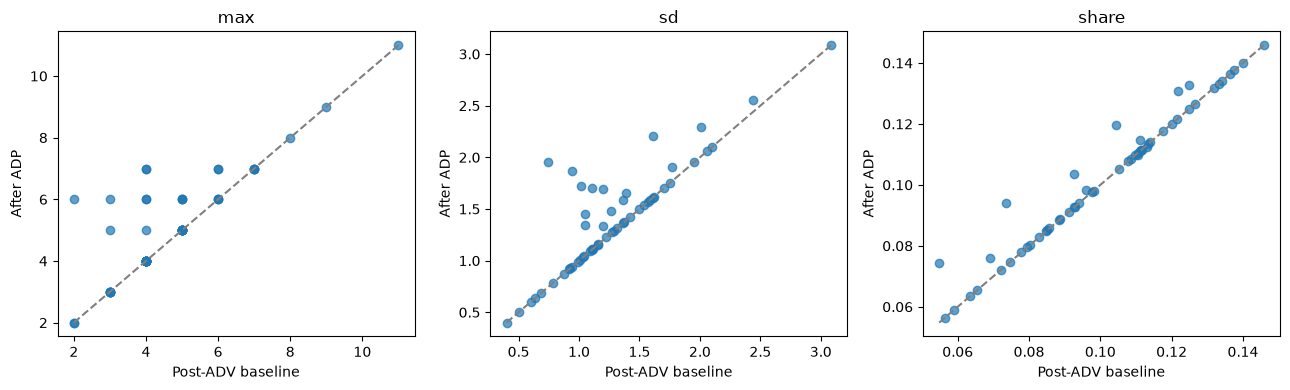

,block,mean_change,ci_low,ci_high
0,ADP,-0.003410,-0.005034,-0.001822
1,Non-ADP,-0.003740,-0.006171,-0.001706
2,Total,-0.007149,-0.011037,-0.003891


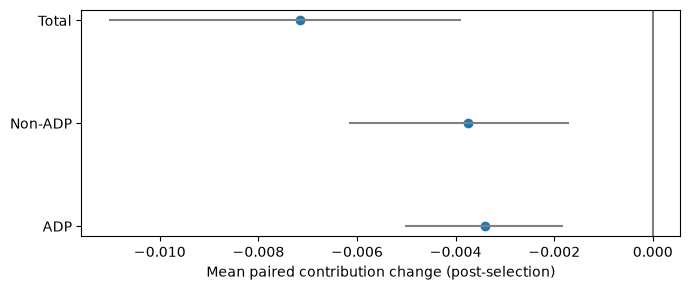

,requested_FPR,calibration_FPR,test_FPR,threshold,After_step55_TPR,After_ADV_TPR,Before_detected,After_detected,n_AI,After_ADP_TPR,After_ADP_detected
0,0.01,0.008418,0.015988,0.653783,0.185185,0.166667,10,9,54,0.129630,7
1,0.05,0.049798,0.038906,0.602644,0.296296,0.296296,16,16,54,0.240741,13
2,0.10,0.099596,0.050044,0.589020,0.296296,0.296296,16,16,54,0.296296,16
3,0.20,0.192703,0.118355,0.520601,0.407407,0.388889,22,21,54,0.388889,21
4,0.30,0.294700,0.233352,0.476262,0.555556,0.537037,30,29,54,0.518519,28
5,0.50,0.497691,0.405241,0.420166,0.703704,0.703704,38,38,54,0.666667,36
6,1.00,1.000000,1.000000,-inf,1.000000,1.000000,54,54,54,1.000000,54


Saved: ../results/causal/C03d_ADP_boost_compensate/1d921b4b832b
Compensation is best-effort. Inspect paired_metrics.csv for remaining token-share drift.


In [9]:
adp_results=[]
for row in final_eval.itertuples():
    checkpoint=adp_dir/'cases'/(adp_hash(str(row.case_id))+'.json')
    if checkpoint.exists(): result=json.loads(checkpoint.read_text())
    else:
        print('Starting',row.case_id,flush=True)
        result=adp_process(row);adp_atomic(checkpoint,result)
    adp_results.append(result)
    print(f"Completed {len(adp_results)}/54: {row.case_id} — {result['status']}",flush=True)
del adp_model
if torch.cuda.is_available(): torch.cuda.empty_cache()
adp_doc.cache_clear()

adp_final=final_eval.copy()
adp_final['text']=[r['text'] for r in adp_results]
adp_final['ADP_status']=[r['status'] for r in adp_results]
adp_x=np.array([adp_vector(t)[0] for t in adp_final.text])
adp_c=np.array([adp_vector(t)[1] for t in adp_final.text])
adp_before_c=np.array([adp_vector(normalize(t))[1] for t in final_eval.text])
adp_final['post_ADP_AI_score']=detector.predict_proba(pd.DataFrame(adp_x,columns=COLS))[:,1]
adp_final.to_csv(adp_dir/'accepted_texts_and_scores.csv',index=False)
pd.DataFrame([dict(case_id=r['case_id'],**v) for r in adp_results for v in r['categories']]).to_csv(adp_dir/'sentence_categories.csv',index=False)
pd.DataFrame([v for r in adp_results for v in r['trials']]).to_csv(adp_dir/'candidate_trials.csv',index=False)
adp_change=adp_c-adp_before_c
pd.DataFrame(adp_change,index=adp_final.case_id,columns=COLS).to_csv(adp_dir/'paired_contribution_changes.csv')
adp_gap=adp_c-(stored_c-stored_g)
pd.DataFrame(adp_gap,index=adp_final.case_id,columns=COLS).to_csv(adp_dir/'case_contribution_gaps.csv')
pd.DataFrame(dict(feature=COLS,human_adjusted_gap=adp_gap.mean(0),contribution_change=adp_change.mean(0))).sort_values('human_adjusted_gap',ascending=False).to_csv(adp_dir/'remaining_contributions.csv',index=False)
summary=[]
for r in adp_results:
    for metric in ['max','sd','share','adp','other']:
        summary.append(dict(case_id=r['case_id'],domain=r['domain'],status=r['status'],metric=metric,
            before=r['baseline'][metric],after=r['metrics'][metric]))
adp_summary=pd.DataFrame(summary);adp_summary.to_csv(adp_dir/'paired_metrics.csv',index=False)
display(adp_final.ADP_status.value_counts())
display(adp_summary.groupby('metric')[['before','after']].mean())
# Paired, genre-stratified bootstrap of selected outputs: descriptive, not held-out inference.
rng=np.random.default_rng(20260909);draws=[]
for _ in range(2000):
    draws.append(np.concatenate([rng.choice(np.flatnonzero(final_eval.domain.eq(g)),size=sum(final_eval.domain.eq(g)),replace=True) for g in sorted(final_eval.domain.unique())]))
draws=np.array(draws)
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,metric in zip(axes,['max','sd','share']):
    z=adp_summary[adp_summary.metric.eq(metric)].set_index('case_id').loc[final_eval.case_id]
    ax.scatter(z.before,z.after,alpha=.7);lo=min(z.before.min(),z.after.min());hi=max(z.before.max(),z.after.max())
    ax.plot([lo,hi],[lo,hi],'--',color='gray');ax.set(xlabel='Post-ADV baseline',ylabel='After ADP',title=metric)
def adp_save(fig,stem):
    fig.tight_layout()
    for folder in [adp_dir,ROOT/'figures']:
        for ext in ['pdf','png']: fig.savefig(folder/f'C03d_ADP_{stem}.{ext}',dpi=300,bbox_inches='tight')
    plt.show()
adp_save(fig,'boost_compensate_metrics')
rows=[]
for name,ix in [('ADP',ADP_IX),('Non-ADP',OTHER_IX),('Total',list(range(186)))]:
    v=adp_change[:,ix].sum(1);lo,hi=np.quantile(v[draws].mean(1),[.025,.975])
    rows.append(dict(block=name,mean_change=v.mean(),ci_low=lo,ci_high=hi))
block=pd.DataFrame(rows);block.to_csv(adp_dir/'block_changes.csv',index=False);display(block)
fig,ax=plt.subplots(figsize=(7,3));y=np.arange(len(block))
ax.hlines(y,block.ci_low,block.ci_high,color='gray');ax.scatter(block.mean_change,y)
ax.set_yticks(y,block.block);ax.axvline(0,color='gray');ax.set_xlabel('Mean paired contribution change (post-selection)')
adp_save(fig,'boost_compensate_contributions')
# Reuse original fixed validation thresholds; no human rescoring or recalibration.
ops=pd.read_csv(ACCEPTED_DIR/'TPR_staircase.csv')
ops['After_ADP_TPR']=[(adp_final.post_ADP_AI_score>t).mean() for t in ops.threshold]
ops['After_ADP_detected']=[int((adp_final.post_ADP_AI_score>t).sum()) for t in ops.threshold]
ops.to_csv(adp_dir/'TPR_staircase.csv',index=False);display(ops)
print('Saved:',adp_dir)
print('Compensation is best-effort. Inspect paired_metrics.csv for remaining token-share drift.')


The treatment exports `accepted_texts_and_scores.csv`, `sentence_categories.csv`, `candidate_trials.csv`, per-case JSON logs, `paired_metrics.csv`, contribution tables, and the fixed-threshold TPR staircase under the printed ADP run directory. `post_ADP_AI_score` is the new score column; `after_AI_score` remains the incoming post-ADV score. Existing `candidate_id` records the earlier ADV swap, while ADP edit details are in the case JSON files.

Paper plots are saved as PDF and PNG with stems `C03d_ADP_boost_compensate_metrics` and `C03d_ADP_boost_compensate_contributions`. Bootstrap intervals are descriptive after selection on the development cohort. No ADP outcome has been precomputed or inserted into this notebook.


,documents
ADP_status,
no_reachable_boost_within_bounds,25
accepted,15
no_final_acceptance,14



Compensation recovery — accepted documents only:


,case_id,domain,compensation_edits,before_share,boost_only_share,final_share,boost_abs_drift_pp,final_abs_drift_pp,recovered_drift_pp
8,gate_0048,news,0,0.073529,0.094203,0.094203,2.067349,2.067349,0.000000
4,gate_0022,abstracts,1,0.054795,0.080537,0.074324,2.574239,1.952980,0.621259
11,gate_0069,abstracts,0,0.104348,0.119658,0.119658,1.531029,1.531029,0.000000
14,gate_0093,news,1,0.092593,0.110429,0.103659,1.783686,1.106594,0.677091
9,gate_0066,news,0,0.121693,0.130890,0.130890,0.919693,0.919693,0.000000
1,gate_0015,abstracts,0,0.125000,0.132701,0.132701,0.770142,0.770142,0.000000
7,gate_0025,recipes,0,0.068966,0.076046,0.076046,0.708011,0.708011,0.000000
13,gate_0076,news,1,0.111111,0.117647,0.114706,0.653595,0.359477,0.294118
5,gate_0023,books,2,0.095847,0.104430,0.098413,0.858373,0.256605,0.601768
12,gate_0070,books,1,0.110638,0.113924,0.109705,0.328575,0.093366,0.235210


10/15 accepted documents received compensation edits.

Accepted edit spans:


,case_id,phase,sentence,source,replacement,kind
0,gate_0001,boost,1,the increasing,the growth of,PPDB
1,gate_0001,boost,1,generation units,units for generation,compound_expand
2,gate_0001,compensate,2,constraints on,restrictions to,PPDB
3,gate_0001,compensate,3,for the management of,for managing,PPDB
4,gate_0015,boost,3,are discussed,is under discussion,PPDB
5,gate_0015,boost,3,presented,available for consideration,PPDB
6,gate_0016,boost,9,questions of,of issues of,PPDB
7,gate_0016,compensate,6,about his,concerning his,PPDB
8,gate_0021,boost,4,joining,accessions to,PPDB
9,gate_0021,compensate,10,engage in dialogue,have dialogue,PPDB



The 14 no-final-acceptance cases do not have a saved breakdown of every final rejection condition; these logs cannot uniquely attribute those rejections without further reconstruction.


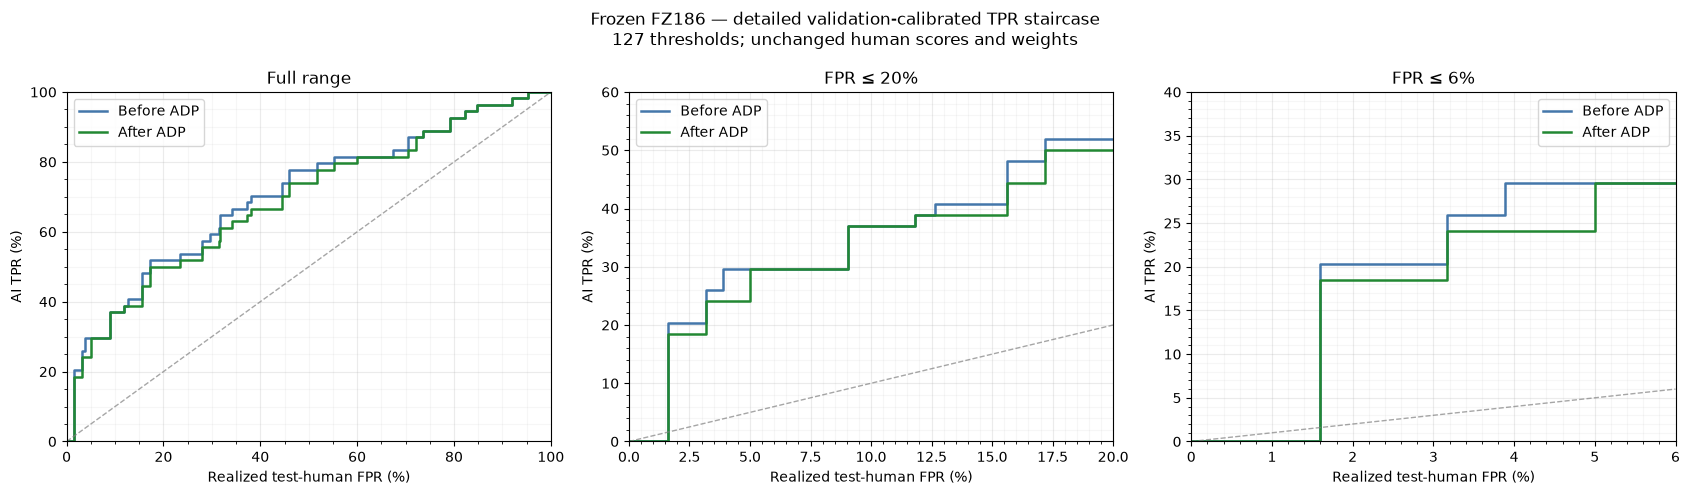

Saved 127 operating points.
This sweeps calibration-derived thresholds; it is not the full empirical ROC.

Top 30 remaining AI-directed contribution gaps:


,feature,before_gap,human_adjusted_gap,ci_low,ci_high,contribution_change,change_ci_low,change_ci_high,fraction_AI_directed
150,pos_NUM_token_share,0.004195,0.004222,0.001968,0.006421,2.633823e-05,-0.000092,0.000138,0.685185
151,pos_NUM_sentence_mean,0.003262,0.003301,0.001254,0.005357,3.973262e-05,-0.000034,0.000120,0.592593
152,pos_NUM_sentence_std,0.003099,0.003119,0.001624,0.004644,1.971286e-05,-0.000077,0.000113,0.685185
120,pos_ADJ_sentence_std,0.003213,0.003045,0.001021,0.005075,-1.681356e-04,-0.000518,0.000073,0.759259
12,share_long_words,0.002948,0.002838,0.001675,0.003983,-1.093855e-04,-0.000268,0.000029,0.759259
134,pos_CCONJ_token_share,0.003025,0.002832,0.001701,0.003924,-1.931083e-04,-0.000353,-0.000038,0.629630
23,share_unique_words,0.002692,0.002660,0.000008,0.005894,-3.234415e-05,-0.000216,0.000179,0.407407
153,pos_NUM_sentence_max,0.002450,0.002450,0.001266,0.003611,-3.613960e-07,-0.000081,0.000078,0.666667
125,pos_ADP_sentence_max,0.004079,0.002337,0.001015,0.003615,-1.742043e-03,-0.002597,-0.000947,0.648148
129,pos_ADV_sentence_max,0.002536,0.002312,0.000750,0.003871,-2.235290e-04,-0.000605,0.000055,0.666667


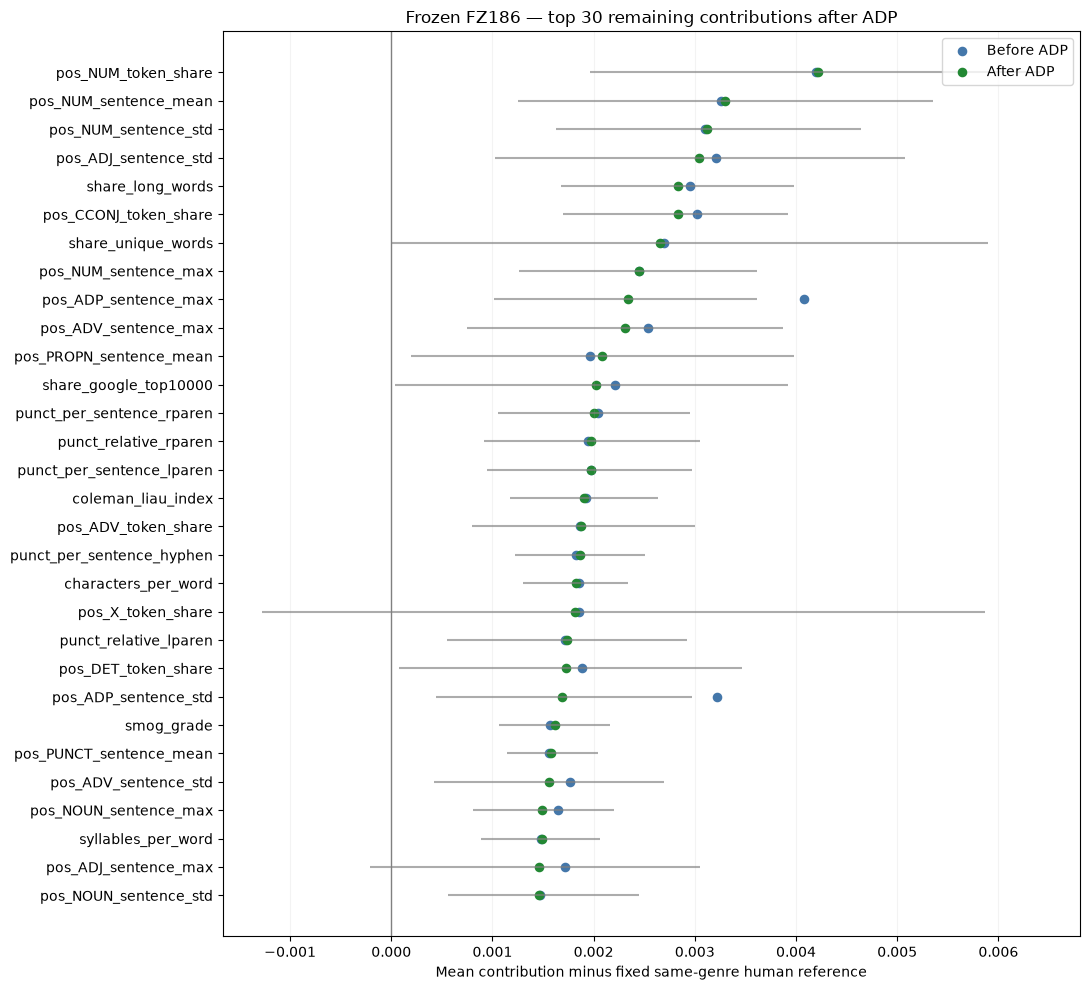


Intervals are genre-stratified document-bootstrap intervals with fixed human references, descriptive after selection.
Saved CSVs: ../results/causal/C03d_ADP_boost_compensate/1d921b4b832b
Saved PDF/PNG figures: ../figures


In [11]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Uses the completed run selected in your current kernel.
D = Path(adp_dir)
FIG = Path(ROOT) / "figures"
FIG.mkdir(parents=True, exist_ok=True)

texts = pd.read_csv(D / "accepted_texts_and_scores.csv", keep_default_na=False)
ops = pd.read_csv(D / "TPR_staircase.csv")
gaps = pd.read_csv(D / "case_contribution_gaps.csv", index_col=0)
changes = pd.read_csv(D / "paired_contribution_changes.csv", index_col=0)

ids = texts.case_id.astype(str).tolist()
gaps.index = gaps.index.astype(str)
changes.index = changes.index.astype(str)
gaps = gaps.loc[ids]
changes = changes.loc[ids, gaps.columns]
assert len(texts) == 54 and texts.case_id.is_unique
assert gaps.shape == changes.shape == (54, 186)
assert np.isfinite(gaps.to_numpy()).all()

def save_figure(fig, stem):
    fig.tight_layout()
    for folder in (D, FIG):
        for ext in ("pdf", "png"):
            fig.savefig(
                folder / f"{stem}.{ext}",
                dpi=300, bbox_inches="tight"
            )
    plt.show()

# ── Compensation and accepted edits: saved checkpoints only ──
records = [
    json.loads(p.read_text())
    for p in sorted((D / "cases").glob("*.json"))
]
records = {str(r["case_id"]): r for r in records}
assert set(ids) <= set(records)
records = [records[cid] for cid in ids]

display(texts.ADP_status.value_counts().rename("documents").to_frame())

comp_rows, edit_rows = [], []
for r in records:
    if r["status"] != "accepted":
        continue
    before = r["baseline"]["share"]
    boosted = r["boost_metrics"]["share"]
    final = r["metrics"]["share"]
    comp_rows.append({
        "case_id": r["case_id"],
        "domain": r["domain"],
        "compensation_edits": len(r["compensation_edits"]),
        "before_share": before,
        "boost_only_share": boosted,
        "final_share": final,
        "boost_abs_drift_pp": 100 * abs(boosted - before),
        "final_abs_drift_pp": 100 * abs(final - before),
        "recovered_drift_pp": 100 * (
            abs(boosted - before) - abs(final - before)
        ),
    })
    for phase, key in [
        ("boost", "boost_edits"),
        ("compensate", "compensation_edits"),
    ]:
        for e in r[key]:
            edit_rows.append({
                "case_id": r["case_id"],
                "phase": phase,
                "sentence": e["sentence"],
                "source": e["source"],
                "replacement": e["replacement"],
                "kind": e["kind"],
            })

comp = pd.DataFrame(comp_rows)
edits = pd.DataFrame(edit_rows)
comp.to_csv(D / "compensation_recovery.csv", index=False)
edits.to_csv(D / "accepted_edit_spans.csv", index=False)

if not comp.empty:
    print("\nCompensation recovery — accepted documents only:")
    display(comp.sort_values("final_abs_drift_pp", ascending=False))
    print(
        f"{comp.compensation_edits.gt(0).sum()}/{len(comp)} accepted "
        "documents received compensation edits."
    )
    print("\nAccepted edit spans:")
    with pd.option_context("display.max_colwidth", 100, "display.max_rows", 200):
        display(edits)

print(
    "\nThe 14 no-final-acceptance cases do not have a saved breakdown "
    "of every final rejection condition; these logs cannot uniquely "
    "attribute those rejections without further reconstruction."
)

# ── TPR staircase at the saved validation-calibrated thresholds ──
# This is a staircase through sampled operating points, not a full ROC.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

D = Path(adp_dir)
FIG = Path(ROOT) / "figures"
FIG.mkdir(parents=True, exist_ok=True)

ai = pd.read_csv(D / "accepted_texts_and_scores.csv")
human_cache = Path(ACCEPTED_DIR).parent.parent / "frozen_human_scores"

# Match cached scores to the exact frozen manifests.
def load_human_scores(split):
    manifest = pd.read_csv(Path(RUN_DIR) / f"human_{split}_manifest.csv")
    matches = []

    for path in sorted(human_cache.glob(f"{split}_*.csv")):
        frame = pd.read_csv(path)
        if not {"source_id", "score", "weight"} <= set(frame.columns):
            continue
        if (
            frame.source_id.astype(str).tolist()
            == manifest.source_id.astype(str).tolist()
            and np.allclose(frame.weight, manifest.weight, atol=1e-12, rtol=0)
        ):
            matches.append((path, frame))

    if not matches:
        raise FileNotFoundError(
            f"No matching saved {split} scores in {human_cache}. "
            "Set human_cache to C03c's frozen_human_scores directory."
        )

    # Multiple equivalent copies are fine; conflicting scores need resolution.
    reference = matches[0][1]
    for path, frame in matches[1:]:
        np.testing.assert_allclose(
            frame.score, reference.score, atol=1e-12, rtol=0,
            err_msg=f"Conflicting frozen human scores: {path}"
        )
    assert np.isclose(reference.weight.sum(), 1)
    assert np.isfinite(reference.score).all()
    return reference

cal = load_human_scores("calibration")
human = load_human_scores("test")

before = ai.after_AI_score.to_numpy()
after = ai.post_ADP_AI_score.to_numpy()
assert len(before) == len(after) == 54
assert np.isfinite(before).all() and np.isfinite(after).all()

# Strict score > threshold, exactly as in the original evaluation.
thresholds = np.r_[np.inf, np.unique(cal.score.to_numpy())[::-1], -np.inf]
rows = []

for threshold in thresholds:
    rows.append({
        "threshold": threshold,
        "calibration_FPR": cal.loc[cal.score > threshold, "weight"].sum(),
        "test_FPR": human.loc[human.score > threshold, "weight"].sum(),
        "before_TPR": (before > threshold).mean(),
        "after_TPR": (after > threshold).mean(),
        "before_detected": int((before > threshold).sum()),
        "after_detected": int((after > threshold).sum()),
        "n_AI": len(ai),
    })

staircase = pd.DataFrame(rows)
staircase.to_csv(D / "detailed_calibrated_TPR_staircase.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
panels = [
    (1.00, 1.00, "Full range"),
    (.20, .60, "FPR ≤ 20%"),
    (.06, .40, "FPR ≤ 6%"),
]

for ax, (xmax, ymax, title) in zip(axes, panels):
    for column, label, color in [
        ("before_TPR", "Before ADP", "#4477AA"),
        ("after_TPR", "After ADP", "#228833"),
    ]:
        ax.step(
            100 * staircase.test_FPR,
            100 * staircase[column],
            where="post", label=label, color=color, lw=1.8,
        )
    ax.plot([0, 100 * xmax], [0, 100 * xmax],
            "--", color="gray", lw=1, alpha=.7)
    ax.set(
        xlim=(0, 100 * xmax),
        ylim=(0, 100 * ymax),
        xlabel="Realized test-human FPR (%)",
        ylabel="AI TPR (%)",
        title=title,
    )
    ax.minorticks_on()
    ax.grid(which="major", alpha=.25)
    ax.grid(which="minor", alpha=.10)
    ax.legend()

fig.suptitle(
    "Frozen FZ186 — detailed validation-calibrated TPR staircase\n"
    f"{len(thresholds)} thresholds; unchanged human scores and weights",
    fontsize=12,
)
fig.tight_layout()

for folder in (D, FIG):
    for ext in ("pdf", "png"):
        fig.savefig(
            folder / f"C03d_ADP_detailed_TPR_staircase.{ext}",
            dpi=300, bbox_inches="tight",
        )
plt.show()

print(f"Saved {len(staircase)} operating points.")
print("This sweeps calibration-derived thresholds; it is not the full empirical ROC.")
# ── Remaining human-adjusted contributions across all 186 features ──
# Same fixed human references: before gap = after gap - paired change.
after = gaps.to_numpy(dtype=float)
delta = changes.to_numpy(dtype=float)
before = after - delta
genres = texts.domain.astype(str).to_numpy()

B = 3000
rng = np.random.default_rng(20260910)
boot_after = np.zeros((B, after.shape[1]))
boot_delta = np.zeros_like(boot_after)

for genre in sorted(set(genres)):
    ix = np.flatnonzero(genres == genre)
    draws = rng.choice(ix, size=(B, len(ix)), replace=True)
    weight = len(ix) / len(ids)
    boot_after += weight * after[draws].mean(axis=1)
    boot_delta += weight * delta[draws].mean(axis=1)

lo, hi = np.quantile(boot_after, [.025, .975], axis=0)
dlo, dhi = np.quantile(boot_delta, [.025, .975], axis=0)

ranking = pd.DataFrame({
    "feature": gaps.columns,
    "before_gap": before.mean(axis=0),
    "human_adjusted_gap": after.mean(axis=0),
    "ci_low": lo,
    "ci_high": hi,
    "contribution_change": delta.mean(axis=0),
    "change_ci_low": dlo,
    "change_ci_high": dhi,
    "fraction_AI_directed": (after > 0).mean(axis=0),
}).sort_values("human_adjusted_gap", ascending=False)

ranking.to_csv(D / "remaining_contributions_with_CI.csv", index=False)
print("\nTop 30 remaining AI-directed contribution gaps:")
display(ranking.head(30))

top = ranking.head(30).iloc[::-1]
y = np.arange(len(top))
fig, ax = plt.subplots(figsize=(11, 10))
ax.hlines(y, top.ci_low, top.ci_high, color="gray", alpha=.65)
ax.scatter(top.before_gap, y, color="#4477AA", label="Before ADP", s=35)
ax.scatter(
    top.human_adjusted_gap, y,
    color="#228833", label="After ADP", s=35
)
ax.set_yticks(y, top.feature)
ax.axvline(0, color="gray", lw=1)
ax.set(
    xlabel="Mean contribution minus fixed same-genre human reference",
    title="Frozen FZ186 — top 30 remaining contributions after ADP",
)
ax.legend()
ax.grid(axis="x", alpha=.15)
save_figure(fig, "C03d_ADP_remaining_contributions")

print(
    "\nIntervals are genre-stratified document-bootstrap intervals "
    "with fixed human references, descriptive after selection."
)
print("Saved CSVs:", D)
print("Saved PDF/PNG figures:", FIG)

In [12]:
examples = [
    "There were 22 participants.",
    "There were twenty-two participants.",
    "There were 105 participants.",
    "There were one hundred and five participants.",
]

for text in examples:
    doc = nlp(text)
    tokens = [t for t in doc if not t.is_space]
    nums = [t.text for t in tokens if t.pos_ == "NUM"]
    print(text)
    print("Tags:", [(t.text, t.pos_) for t in tokens])
    print(f"NUM count: {len(nums)} | token share: {len(nums)/len(tokens):.4f}\n")

There were 22 participants.
Tags: [('There', 'PRON'), ('were', 'VERB'), ('22', 'NUM'), ('participants', 'NOUN'), ('.', 'PUNCT')]
NUM count: 1 | token share: 0.2000

There were twenty-two participants.
Tags: [('There', 'PRON'), ('were', 'VERB'), ('twenty', 'NUM'), ('-', 'PUNCT'), ('two', 'NUM'), ('participants', 'NOUN'), ('.', 'PUNCT')]
NUM count: 2 | token share: 0.2857

There were 105 participants.
Tags: [('There', 'PRON'), ('were', 'VERB'), ('105', 'NUM'), ('participants', 'NOUN'), ('.', 'PUNCT')]
NUM count: 1 | token share: 0.2000

There were one hundred and five participants.
Tags: [('There', 'PRON'), ('were', 'VERB'), ('one', 'NUM'), ('hundred', 'NUM'), ('and', 'CCONJ'), ('five', 'NUM'), ('participants', 'NOUN'), ('.', 'PUNCT')]
NUM count: 3 | token share: 0.3750



In [13]:
# NUM pilot: deterministic digit <-> word conversion.
# Input: the completed, accepted -1.0 ADP run in adp_dir.
from pathlib import Path
from functools import lru_cache
import hashlib, json, re
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display

NUM_PARENT = Path(adp_dir)
parent_contract = json.loads((NUM_PARENT / "contract.json").read_text())
assert parent_contract["config"]["likelihood_floor"] == -1.0
num_input = pd.read_csv(
    NUM_PARENT / "accepted_texts_and_scores.csv", keep_default_na=False
)
assert len(num_input) == 54 and num_input.case_id.is_unique
assert len(COLS) == 186

# Canonical renderings provide exact value checks without another dependency.
ONES = (
    "zero one two three four five six seven eight nine ten eleven twelve "
    "thirteen fourteen fifteen sixteen seventeen eighteen nineteen"
).split()
TENS = "zero ten twenty thirty forty fifty sixty seventy eighty ninety".split()

def num_words(n, british=False):
    if n < 20:
        return ONES[n]
    if n < 100:
        return TENS[n // 10] + ("-" + ONES[n % 10] if n % 10 else "")
    if n < 1000:
        return (
            ONES[n // 100] + " hundred"
            + ((" and " if british else " ") + num_words(n % 100, british)
               if n % 100 else "")
        )
    remainder = n % 1000
    connector = " and " if british and 0 < remainder < 100 else " "
    return (
        ONES[n // 1000] + " thousand"
        + (connector + num_words(remainder, british) if remainder else "")
    )

NUM_LIMIT = 9999
word_values = {}
for value in range(NUM_LIMIT + 1):
    for british in (False, True):
        phrase = num_words(value, british)
        assert phrase not in word_values or word_values[phrase] == value
        word_values[phrase] = value

vocabulary = set(ONES + TENS[2:] + ["hundred", "thousand", "and"])
word_atom = r"\b(?:" + "|".join(sorted(vocabulary, key=len, reverse=True)) + r")\b"
word_pattern = re.compile(
    word_atom + r"(?:(?:[ \t]+|-)" + word_atom + r")*", re.I
)
digit_pattern = re.compile(r"\b(?:0|[1-9]\d{0,3})\b")

def num_hash(obj):
    return hashlib.sha256(
        json.dumps(obj, sort_keys=True, ensure_ascii=False).encode()
    ).hexdigest()

def num_atomic(path, obj):
    temp = path.with_suffix(".tmp")
    temp.write_text(json.dumps(obj, ensure_ascii=False, indent=2))
    temp.replace(path)

scorer = json.loads(
    (Path(ROOT) / "results/causal/C02r_discovery_gated_punctuation/"
     "treatment_contract.json").read_text()
)
assert re.fullmatch(r"[0-9a-fA-F]{40}", scorer["scorer_revision"])

num_device = "cuda" if torch.cuda.is_available() else "cpu"
# Record the actual executed cell, not the notebook's potentially unsaved contents.
num_cell_source = get_ipython().history_manager.input_hist_raw[-1]
num_contract = dict(
    version="NUM_cardinal_conversion_v1",
    parent_contract_sha256=hashlib.sha256(
        (NUM_PARENT / "contract.json").read_bytes()
    ).hexdigest(),
    input_sha256=hashlib.sha256(
        (NUM_PARENT / "accepted_texts_and_scores.csv").read_bytes()
    ).hexdigest(),
    code_sha256=hashlib.sha256(num_cell_source.encode()).hexdigest(),
    max_integer=NUM_LIMIT,
    likelihood_floor=-1.0,
    scorer=scorer["scorer"],
    revision=scorer["scorer_revision"],
    device=num_device,
    torch=torch.__version__,
    policy="one swap; NUM improvement; combined non-NUM nonincrease",
)
NUM_OUT = (
    Path(ROOT) / "results/causal/C03d_NUM_cardinal_conversion"
    / num_hash(num_contract)[:12]
)
NUM_OUT.mkdir(parents=True, exist_ok=True)
for name in ("cases", "vectors", "likelihood"):
    (NUM_OUT / name).mkdir(exist_ok=True)
contract_path = NUM_OUT / "contract.json"
if contract_path.exists():
    assert json.loads(contract_path.read_text()) == num_contract
else:
    num_atomic(contract_path, num_contract)

NUM_IX = [i for i, c in enumerate(COLS) if c.startswith("pos_NUM_")]
NON_NUM_IX = [i for i in range(len(COLS)) if i not in NUM_IX]

def num_vectors(text):
    path = NUM_OUT / "vectors" / (num_hash(text) + ".npz")
    if path.exists():
        with np.load(path, allow_pickle=False) as f:
            return f["x"], f["c"]
    frame = full_frame([text])
    x, c = frame.iloc[0].to_numpy(), contributions(frame)[0]
    temp = path.with_suffix(".tmp")
    with temp.open("wb") as f:
        np.savez_compressed(f, x=x, c=c)
    temp.replace(path)
    return x, c

def num_candidates(text):
    doc = nlp(text)
    proposals = []
    for match in digit_pattern.finditer(text):
        value = int(match.group())
        for replacement in sorted({
            num_words(value, False), num_words(value, True)
        }):
            proposals.append((match.start(), match.end(), value,
                              replacement, "digits_to_words"))

    for match in word_pattern.finditer(text):
        phrase = re.sub(r"[ \t]+", " ", match.group().lower())
        if phrase in word_values:
            value = word_values[phrase]
            proposals.append((match.start(), match.end(), value,
                              str(value), "words_to_digits"))

    sentences = list(doc.sents)
    for a, b, value, replacement, direction in sorted(set(proposals)):
        span = doc.char_span(a, b, alignment_mode="strict")
        if span is None or not any(t.pos_ == "NUM" for t in span):
            continue
        if any(t.pos_ == "PROPN" for t in span):
            continue

        # Reject dates, times, money, percentages, names, etc.
        # Entity boundaries must match the whole number if an entity overlaps.
        entities = [e for e in doc.ents if e.start_char < b and e.end_char > a]
        if any(e.label_ != "CARDINAL" or e.start_char != a or e.end_char != b
               for e in entities):
            continue

        # Avoid fragments of signed values, ranges, decimals, formatted numbers,
        # fractions, ordinals, versions, and hyphenated constructions.
        left = text[a-1] if a else ""
        right = text[b:b+1]
        if left and (left.isalnum() or left in "_+-−–—/.,:$£€"):
            continue
        if right and (right.isalnum() or right in "_+-−–—/:%"):
            continue
        if re.match(r"[.,]\d", text[b:]):
            continue

        previous = doc[span.start-1] if span.start else None
        following = doc[span.end] if span.end < len(doc) else None
        label_words = {
            "step", "chapter", "section", "figure", "table", "version",
            "model", "page", "item", "number", "no", "id", "isbn",
        }
        if previous is not None and previous.lower_ in label_words:
            continue
        if any(t is not None and t.pos_ == "NUM"
               for t in (previous, following)):
            continue

        # Exact numeric round-trip: never infer or alter the value.
        if direction == "digits_to_words":
            assert int(text[a:b]) == word_values[replacement] == value
            if a == span.sent.start_char:
                replacement = replacement[0].upper() + replacement[1:]
        else:
            assert word_values[
                re.sub(r"[ \t]+", " ", text[a:b].lower())
            ] == int(replacement) == value

        edited = text[:a] + replacement + text[b:]
        new_doc = nlp(edited)
        new_sentences = list(new_doc.sents)
        if len(new_sentences) != len(sentences):
            continue
        si = next(i for i, s in enumerate(sentences)
                  if s.start_char <= a and b <= s.end_char)
        if any(s.text != new_sentences[i].text
               for i, s in enumerate(sentences) if i != si):
            continue
        if [t.text for t in doc if t.dep_ == "neg"] != [
            t.text for t in new_doc if t.dep_ == "neg"
        ]:
            continue
        yield dict(
            a=a, b=b, source=text[a:b], replacement=replacement,
            value=value, direction=direction, text=edited,
            before_sentence=sentences[si].text,
            after_sentence=new_sentences[si].text,
        )

# Same broad/local contextual likelihood definition as ADV.
num_tokenizer = AutoTokenizer.from_pretrained(
    scorer["scorer"], revision=scorer["scorer_revision"], use_fast=True
)
assert num_tokenizer.is_fast
num_model = AutoModelForCausalLM.from_pretrained(
    scorer["scorer"], revision=scorer["scorer_revision"]
).to(num_device).eval()
num_max_length = getattr(num_model.config, "max_position_embeddings", 1024)

def num_logp(left, span, right, local):
    enc = num_tokenizer(
        left + span + right,
        add_special_tokens=False, return_offsets_mapping=True
    )
    ids, offsets = enc["input_ids"], enc["offset_mapping"]
    boundary = len(left) + len(span)
    following = [i for i, (a, b) in enumerate(offsets) if a >= boundary][:8]
    mask = [
        b > len(left) and (not local or a < boundary or i in following)
        for i, (a, b) in enumerate(offsets)
    ]
    if not any(mask):
        return None
    end = max(i for i, keep in enumerate(mask) if keep) + 1
    ids, mask = ids[:end], mask[:end]
    if not left:
        ids = [num_tokenizer.bos_token_id or num_tokenizer.eos_token_id] + ids
        mask = [False] + mask
    if len(ids) > num_max_length or not any(mask[1:]):
        return None
    path = NUM_OUT / "likelihood" / (num_hash([ids, mask]) + ".json")
    if path.exists():
        return json.loads(path.read_text())["logp"]
    with torch.inference_mode():
        x = torch.tensor([ids], device=num_device)
        logits = num_model(x, use_cache=False).logits[:, :-1]
        loss = torch.nn.functional.cross_entropy(
            logits.reshape(-1, logits.shape[-1]),
            x[:, 1:].reshape(-1), reduction="none"
        )
        selected = torch.tensor(mask[1:], dtype=torch.bool, device=num_device)
        value = -float(loss[selected].mean().cpu())
    num_atomic(path, {"logp": value})
    return value

def num_likelihood(text, candidate):
    a, b = candidate["a"], candidate["b"]
    prefix, suffix = text[:a], text[b:]
    left_words = list(re.finditer(r"\S+", prefix))
    right_words = list(re.finditer(r"\S+", suffix))
    left = prefix[left_words[-48].start():] if len(left_words) > 48 else prefix
    right = suffix[:right_words[47].end()] if len(right_words) > 48 else suffix
    deltas = []
    for local in (False, True):
        old = num_logp(left, text[a:b], right, local)
        new = num_logp(left, candidate["replacement"], right, local)
        if old is None or new is None:
            return None
        deltas.append(new - old)
    return deltas

num_results = []
for row in num_input.itertuples():
    checkpoint = NUM_OUT / "cases" / (num_hash(str(row.case_id)) + ".json")
    if checkpoint.exists():
        result = json.loads(checkpoint.read_text())
    else:
        text = normalize(row.text)
        bx, bc = num_vectors(text)
        baseline_score = float(
            detector.predict_proba(pd.DataFrame([bx], columns=COLS))[0, 1]
        )
        assert np.isclose(
            baseline_score, row.post_ADP_AI_score, atol=1e-8, rtol=0
        ), "Post-ADP baseline replay mismatch."
        trials, eligible = [], []
        for candidate in num_candidates(text):
            ax, ac = num_vectors(candidate["text"])
            delta = ac - bc
            target_delta = float(delta[NUM_IX].sum())
            other_delta = float(delta[NON_NUM_IX].sum())
            changed_NUM = bool(np.any(
                np.abs(ax[NUM_IX] - bx[NUM_IX]) > 1e-12
            ))
            record_trial = {
                **candidate,
                "NUM_change": target_delta,
                "non_NUM_change": other_delta,
                "raw_NUM_changed": changed_NUM,
            }
            if not changed_NUM:
                record_trial["status"] = "no_NUM_feature_change"
            elif target_delta >= -1e-12 or other_delta > 1e-12:
                record_trial["status"] = "contribution_gate"
            else:
                ll = num_likelihood(text, candidate)
                record_trial["likelihood_deltas"] = ll
                record_trial["status"] = (
                    "eligible" if ll is not None and min(ll) >= -1.0
                    else "likelihood_gate"
                )
                if record_trial["status"] == "eligible":
                    eligible.append(record_trial)
            trials.append(record_trial)

        eligible.sort(key=lambda c: (
            c["NUM_change"], -c["likelihood_deltas"][1],
            c["a"], c["b"], c["replacement"]
        ))
        chosen = eligible[0] if eligible else None
        result = dict(
            case_id=row.case_id,
            text=chosen["text"] if chosen else text,
            status="accepted" if chosen else "unchanged",
            selected=chosen, trials=trials,
        )
        num_atomic(checkpoint, result)
    num_results.append(result)
    print(
        f"{len(num_results)}/54 | {row.case_id} | {result['status']} | "
        f"{len(result['trials'])} candidates",
        flush=True
    )

del num_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()

num_final = num_input.copy()
num_final["text"] = [r["text"] for r in num_results]
num_final["NUM_status"] = [r["status"] for r in num_results]
after_x = np.array([num_vectors(t)[0] for t in num_final.text])
after_c = np.array([num_vectors(t)[1] for t in num_final.text])
before_c = np.array([num_vectors(normalize(t))[1] for t in num_input.text])
num_final["post_NUM_AI_score"] = detector.predict_proba(
    pd.DataFrame(after_x, columns=COLS)
)[:, 1]
num_final.to_csv(NUM_OUT / "accepted_texts_and_scores.csv", index=False)

paired = after_c - before_c
pd.DataFrame(
    paired, index=num_final.case_id, columns=COLS
).to_csv(NUM_OUT / "paired_contribution_changes.csv")
parent_gaps = pd.read_csv(
    NUM_PARENT / "case_contribution_gaps.csv", index_col=0
).loc[num_final.case_id, COLS]
new_gaps = parent_gaps.to_numpy() + paired
pd.DataFrame(
    new_gaps, index=num_final.case_id, columns=COLS
).to_csv(NUM_OUT / "case_contribution_gaps.csv")
ranking = pd.DataFrame({
    "feature": COLS,
    "human_adjusted_gap": new_gaps.mean(0),
    "contribution_change": paired.mean(0),
}).sort_values("human_adjusted_gap", ascending=False)
ranking.to_csv(NUM_OUT / "remaining_contributions.csv", index=False)

trial_rows = [
    {"case_id": r["case_id"], **c}
    for r in num_results for c in r["trials"]
]
pd.DataFrame(trial_rows).to_csv(NUM_OUT / "candidate_trials.csv", index=False)
selected_rows = [
    {"case_id": r["case_id"], **r["selected"]}
    for r in num_results if r["selected"] is not None
]
pd.DataFrame(selected_rows).to_csv(NUM_OUT / "selected_conversions.csv", index=False)

ops = pd.read_csv(NUM_PARENT / "TPR_staircase.csv")
ops["After_NUM_TPR"] = [
    (num_final.post_NUM_AI_score > threshold).mean()
    for threshold in ops.threshold
]
ops["After_NUM_detected"] = [
    int((num_final.post_NUM_AI_score > threshold).sum())
    for threshold in ops.threshold
]
ops.to_csv(NUM_OUT / "TPR_staircase.csv", index=False)

display(num_final.NUM_status.value_counts().to_frame("documents"))
if selected_rows:
    print("\nAccepted conversions — inspect full sentence context:")
    with pd.option_context("display.max_colwidth", 180):
        display(pd.DataFrame(selected_rows)[[
            "case_id", "source", "replacement", "value",
            "NUM_change", "non_NUM_change",
            "before_sentence", "after_sentence",
        ]])
display(ops)
display(ranking.head(20))
print("\nSaved:", NUM_OUT)
print("No earlier text artifacts were overwritten.")

Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████| 148/148 [00:00<00:00, 7693.30it/s]


1/54 | gate_0001 | unchanged | 0 candidates
2/54 | gate_0003 | unchanged | 0 candidates
3/54 | gate_0004 | unchanged | 12 candidates
4/54 | gate_0005 | unchanged | 1 candidates
5/54 | gate_0007 | unchanged | 0 candidates
6/54 | gate_0015 | unchanged | 2 candidates
7/54 | gate_0016 | unchanged | 0 candidates
8/54 | gate_0017 | unchanged | 0 candidates
9/54 | gate_0018 | unchanged | 5 candidates
10/54 | gate_0019 | unchanged | 1 candidates
11/54 | gate_0020 | unchanged | 0 candidates
12/54 | gate_0021 | unchanged | 0 candidates
13/54 | gate_0022 | unchanged | 0 candidates
14/54 | gate_0023 | unchanged | 1 candidates
15/54 | gate_0024 | unchanged | 2 candidates
16/54 | gate_0025 | unchanged | 5 candidates
17/54 | gate_0026 | unchanged | 0 candidates
18/54 | gate_0027 | accepted | 2 candidates
19/54 | gate_0028 | unchanged | 2 candidates
20/54 | gate_0030 | unchanged | 3 candidates
21/54 | gate_0035 | unchanged | 0 candidates
22/54 | gate_0037 | unchanged | 10 candidates
23/54 | gate_0038 

,documents
NUM_status,
unchanged,51
accepted,3



Accepted conversions — inspect full sentence context:


,case_id,source,replacement,value,NUM_change,non_NUM_change,before_sentence,after_sentence
0,gate_0027,300,three hundred,300,-0.013968,-0.015071,"At its peak, the Fife Coalfield boasted over 300 mines, making it one of the most productive coal mining regions in the United Kingdom.","At its peak, the Fife Coalfield boasted over three hundred mines, making it one of the most productive coal mining regions in the United Kingdom."
1,gate_0049,383,three hundred eighty-three,383,-0.001269,-0.000537,"Nutrition Facts Calories, 383 Fat, 29g Cholesterol, 443mg Sodium, 1152mg Carbs, 6g Fiber, 1g Sugars, 3g Protein, 23g","Nutrition Facts Calories, three hundred eighty-three Fat, 29g Cholesterol, 443mg Sodium, 1152mg Carbs, 6g Fiber, 1g Sugars, 3g Protein, 23g"
2,gate_0088,106,one hundred six,106,-0.000077,-0.003478,He levelled at 6-6 with a break of 106 and then took the lead for the first time in the match with a run of 70.,He levelled at 6-6 with a break of one hundred six and then took the lead for the first time in the match with a run of 70.


,requested_FPR,calibration_FPR,test_FPR,threshold,After_step55_TPR,After_ADV_TPR,Before_detected,After_detected,n_AI,After_ADP_TPR,After_ADP_detected,After_NUM_TPR,After_NUM_detected
0,0.01,0.008418,0.015988,0.653783,0.185185,0.166667,10,9,54,0.129630,7,0.129630,7
1,0.05,0.049798,0.038906,0.602644,0.296296,0.296296,16,16,54,0.240741,13,0.240741,13
2,0.10,0.099596,0.050044,0.589020,0.296296,0.296296,16,16,54,0.296296,16,0.296296,16
3,0.20,0.192703,0.118355,0.520601,0.407407,0.388889,22,21,54,0.388889,21,0.388889,21
4,0.30,0.294700,0.233352,0.476262,0.555556,0.537037,30,29,54,0.518519,28,0.518519,28
5,0.50,0.497691,0.405241,0.420166,0.703704,0.703704,38,38,54,0.666667,36,0.666667,36
6,1.00,1.000000,1.000000,-inf,1.000000,1.000000,54,54,54,1.000000,54,1.000000,54


,feature,human_adjusted_gap,contribution_change
150,pos_NUM_token_share,0.004230,8.035665e-06
151,pos_NUM_sentence_mean,0.003269,-3.200367e-05
120,pos_ADJ_sentence_std,0.003016,-2.876186e-05
152,pos_NUM_sentence_std,0.002985,-1.338645e-04
12,share_long_words,0.002859,2.093443e-05
134,pos_CCONJ_token_share,0.002837,4.917451e-06
23,share_unique_words,0.002615,-4.464536e-05
125,pos_ADP_sentence_max,0.002333,-3.891201e-06
153,pos_NUM_sentence_max,0.002324,-1.257699e-04
129,pos_ADV_sentence_max,0.002309,-3.539357e-06



Saved: ../results/causal/C03d_NUM_cardinal_conversion/7ceb612bac6d
No earlier text artifacts were overwritten.


In [14]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display

D = Path(NUM_OUT)
records = [
    json.loads(p.read_text())
    for p in sorted((D / "cases").glob("*.json"))
]

case_rows, trial_rows = [], []
for r in records:
    selected = r.get("selected")
    case_rows.append({
        "case_id": r["case_id"],
        "result": r["status"],
        "candidate_count": len(r["trials"]),
    })

    for c in r["trials"]:
        selected_here = selected is not None and (
            c["a"], c["b"], c["replacement"]
        ) == (
            selected["a"], selected["b"], selected["replacement"]
        )

        num_improves = c["NUM_change"] < -1e-12
        other_ok = c["non_NUM_change"] <= 1e-12
        ll = c.get("likelihood_deltas")

        if not c["raw_NUM_changed"]:
            reason = "No NUM feature change"
        elif not num_improves and not other_ok:
            reason = "NUM not improved + non-NUM increased"
        elif not num_improves:
            reason = "NUM not improved"
        elif not other_ok:
            reason = "Non-NUM increased only"
        elif c["status"] == "likelihood_gate":
            reason = (
                "Likelihood window unscorable"
                if ll is None else "Likelihood below -1.0"
            )
        elif selected_here:
            reason = "Selected"
        else:
            reason = "Eligible, another candidate selected"

        trial_rows.append({
            "case_id": r["case_id"],
            "reason": reason,
            "source": c["source"],
            "replacement": c["replacement"],
            "direction": c["direction"],
            "value": c["value"],
            "NUM_change": c["NUM_change"],
            "non_NUM_change": c["non_NUM_change"],
            "total_change": c["NUM_change"] + c["non_NUM_change"],
            "broad_delta": ll[0] if ll is not None else np.nan,
            "local_delta": ll[1] if ll is not None else np.nan,
            "likelihood_evaluated": ll is not None,
            "before_sentence": c["before_sentence"],
            "after_sentence": c["after_sentence"],
        })

cases = pd.DataFrame(case_rows).sort_values("case_id")
trials = pd.DataFrame(trial_rows)

print("DOCUMENT COVERAGE")
display(pd.DataFrame({
    "category": [
        "No candidates reached scoring",
        "Candidates present, no selected conversion",
        "Accepted",
    ],
    "documents": [
        cases.candidate_count.eq(0).sum(),
        (cases.candidate_count.gt(0) & cases.result.ne("accepted")).sum(),
        cases.result.eq("accepted").sum(),
    ],
}))

if trials.empty:
    print("No scored candidates were saved.")
else:
    print("\nCANDIDATE OUTCOMES")
    display(
        trials.groupby("reason").agg(
            candidates=("case_id", "size"),
            documents=("case_id", "nunique"),
        ).sort_values("candidates", ascending=False)
    )
    print("Document counts can overlap across rejection reasons.")

    # Would a net-benefit rule admit additional contribution-stage candidates?
    collateral_only = trials.loc[
        trials.reason.eq("Non-NUM increased only")
    ].copy()
    net_benefit = collateral_only.loc[
        collateral_only.total_change.lt(-1e-12)
    ].sort_values("total_change")

    print(
        "\nNUM improves and total contribution falls, "
        "but the strict non-NUM gate rejects:"
    )
    print(
        f"{len(net_benefit)} candidates across "
        f"{net_benefit.case_id.nunique()} documents."
    )
    print(
        "Their likelihood was not evaluated in the original run; "
        "these are potential additional candidates, not accepted edits."
    )

    columns = [
        "case_id", "source", "replacement",
        "NUM_change", "non_NUM_change", "total_change",
        "broad_delta", "local_delta",
        "before_sentence", "after_sentence",
    ]
    with pd.option_context(
        "display.max_colwidth", 180,
        "display.max_rows", None,
        "display.float_format", lambda x: f"{x:.6f}",
    ):
        if not net_benefit.empty:
            display(net_benefit[columns])

        print("\nALL REJECTED CONVERSIONS, GROUPED BY REASON")
        rejected = trials.loc[
            ~trials.reason.isin([
                "Selected", "Eligible, another candidate selected"
            ])
        ]
        for reason, group in rejected.groupby("reason", sort=True):
            print(f"\n{reason} — {len(group)} candidates")
            display(group.sort_values("total_change")[columns])

    trials.to_csv(D / "rejection_audit.csv", index=False)

print("\nDOCUMENTS WITH ZERO SCORED CANDIDATES")
display(cases.loc[cases.candidate_count.eq(0), ["case_id"]])
cases.to_csv(D / "candidate_coverage_audit.csv", index=False)

print(
    "\nImportant: the original candidate generator did not log its early "
    "exclusions (entity checks, numeric formatting, protected labels, etc.). "
    "Zero-candidate documents may have no supported numbers or may have "
    "lost candidates at those checks; these saved logs cannot distinguish them."
)
print("Saved diagnostics:", D)

DOCUMENT COVERAGE


,category,documents
0,No candidates reached scoring,29
1,"Candidates present, no selected conversion",22
2,Accepted,3



CANDIDATE OUTCOMES


,candidates,documents
reason,,
No NUM feature change,84,24
NUM not improved,3,2
Selected,3,3
Likelihood below -1.0,2,1
"Eligible, another candidate selected",1,1
NUM not improved + non-NUM increased,1,1


Document counts can overlap across rejection reasons.

NUM improves and total contribution falls, but the strict non-NUM gate rejects:
0 candidates across 0 documents.
Their likelihood was not evaluated in the original run; these are potential additional candidates, not accepted edits.

ALL REJECTED CONVERSIONS, GROUPED BY REASON

Likelihood below -1.0 — 2 candidates


...


No NUM feature change — 84 candidates


,case_id,source,replacement,NUM_change,non_NUM_change,total_change,broad_delta,local_delta,before_sentence,after_sentence
11,gate_0028,two,2,0.001303,-0.009886,-0.008584,NaN,NaN,This study introduces two innovative methods for multi-organ segmentation using deep learning.,This study introduces 2 innovative methods for multi-organ segmentation using deep learning.
8,gate_0030,two,2,0.000000,-0.007168,-0.007168,NaN,NaN,South Africa's foreign ministry said that the reopening of the embassy would help strengthen bilateral ties and boost economic cooperation between the two nations.,South Africa's foreign ministry said that the reopening of the embassy would help strengthen bilateral ties and boost economic cooperation between the 2 nations.
78,gate_0085,8,eight,0.000288,-0.007038,-0.006750,NaN,NaN,"Ingredients, 1 head of broccoli cut into small florets and 3 cloves of garlic, minced and 1/2 cup of ricotta cheese, 1/4 cup of grated parmesan cheese and 1/4 cup of hot honey ...","Ingredients, 1 head of broccoli cut into small florets and 3 cloves of garlic, minced and 1/2 cup of ricotta cheese, 1/4 cup of grated parmesan cheese and 1/4 cup of hot honey ..."
79,gate_0085,2,two,0.000288,-0.006538,-0.006250,NaN,NaN,"Ingredients, 1 head of broccoli cut into small florets and 3 cloves of garlic, minced and 1/2 cup of ricotta cheese, 1/4 cup of grated parmesan cheese and 1/4 cup of hot honey ...","Ingredients, 1 head of broccoli cut into small florets and 3 cloves of garlic, minced and 1/2 cup of ricotta cheese, 1/4 cup of grated parmesan cheese and 1/4 cup of hot honey ..."
77,gate_0085,3,three,0.000288,-0.006483,-0.006194,NaN,NaN,"Ingredients, 1 head of broccoli cut into small florets and 3 cloves of garlic, minced and 1/2 cup of ricotta cheese, 1/4 cup of grated parmesan cheese and 1/4 cup of hot honey ...","Ingredients, 1 head of broccoli cut into small florets and three cloves of garlic, minced and 1/2 cup of ricotta cheese, 1/4 cup of grated parmesan cheese and 1/4 cup of hot ho..."
60,gate_0081,1,one,0.000000,-0.004167,-0.004167,NaN,NaN,"Delightful Lemon Cake Recipe Ingredients 2 cups all purpose flour 1 ½ teaspoons baking powder ¼ teaspoon salt -3 large eggs, room temperature 1 cup granulated sugar 2 tabl...","Delightful Lemon Cake Recipe Ingredients 2 cups all purpose flour 1 ½ teaspoons baking powder ¼ teaspoon salt -3 large eggs, room temperature 1 cup granulated sugar 2 tabl..."
62,gate_0081,1,one,0.000000,-0.004167,-0.004167,NaN,NaN,"Delightful Lemon Cake Recipe Ingredients 2 cups all purpose flour 1 ½ teaspoons baking powder ¼ teaspoon salt -3 large eggs, room temperature 1 cup granulated sugar 2 tabl...","Delightful Lemon Cake Recipe Ingredients 2 cups all purpose flour 1 ½ teaspoons baking powder ¼ teaspoon salt -3 large eggs, room temperature 1 cup granulated sugar 2 tabl..."
58,gate_0081,1,one,0.000000,-0.004167,-0.004167,NaN,NaN,"Delightful Lemon Cake Recipe Ingredients 2 cups all purpose flour 1 ½ teaspoons baking powder ¼ teaspoon salt -3 large eggs, room temperature 1 cup granulated sugar 2 tabl...","Delightful Lemon Cake Recipe Ingredients 2 cups all purpose flour one ½ teaspoons baking powder ¼ teaspoon salt -3 large eggs, room temperature 1 cup granulated sugar 2 ta..."
59,gate_0081,2,two,0.000435,-0.004574,-0.004139,NaN,NaN,"Delightful Lemon Cake Recipe Ingredients 2 cups all purpose flour 1 ½ teaspoons baking powder ¼ teaspoon salt -3 large eggs, room temperature 1 cup granulated sugar 2 tabl...","Delightful Lemon Cake Recipe Ingredients 2 cups all purpose flour 1 ½ teaspoons baking powder ¼ teaspoon salt -3 large eggs, room temperature 1 cup granulated sugar two ta..."
56,gate_0027,one,1,0.000129,-0.004129,-0.004000,NaN,NaN,"At its peak, the Fife Coalfield boasted over 300 mines, making it one of the most productive coal mining regions in the United Kingdom.","At its peak, the Fife Coalfield boasted over 300 mines, making it 1 of the most productive coal mining regions in the United Kingdom."



DOCUMENTS WITH ZERO SCORED CANDIDATES


,case_id
9,gate_0001
4,gate_0003
43,gate_0007
17,gate_0016
10,gate_0017
42,gate_0020
7,gate_0021
31,gate_0022
25,gate_0026
15,gate_0035



Important: the original candidate generator did not log its early exclusions (entity checks, numeric formatting, protected labels, etc.). Zero-candidate documents may have no supported numbers or may have lost candidates at those checks; these saved logs cannot distinguish them.
Saved diagnostics: ../results/causal/C03d_NUM_cardinal_conversion/7ceb612bac6d


In [15]:
examples = [
    "Use 1/3 of the mixture.",
    "Use one-third of the mixture.",
    "Use one third of the mixture.",
    "Use 2/3 of the mixture.",
    "Use two-thirds of the mixture.",
    "Use two thirds of the mixture.",
    "He served from 2016 to 2019.",
    "He served from 2016 to two thousand nineteen.",
    "He served from two thousand sixteen to two thousand nineteen.",
    "He served from twenty sixteen to twenty nineteen.",
]

rows = []
for text in examples:
    doc = nlp(text)
    tokens = [t for t in doc if not t.is_space]
    nums = [t.text for t in tokens if t.pos_ == "NUM"]
    rows.append({
        "text": text,
        "NUM_tokens": nums,
        "NUM_count": len(nums),
        "all_tokens": len(tokens),
        "NUM_share": len(nums) / max(1, len(tokens)),
        "tags": [(t.text, t.pos_) for t in tokens],
    })

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows))

,text,NUM_tokens,NUM_count,all_tokens,NUM_share,tags
0,Use 1/3 of the mixture.,[1/3],1,6,0.166667,"[(Use, VERB), (1/3, NUM), (of, ADP), (the, DET), (mixture, NOUN), (., PUNCT)]"
1,Use one-third of the mixture.,[one],1,8,0.125000,"[(Use, VERB), (one, NUM), (-, PUNCT), (third, NOUN), (of, ADP), (the, DET), (mixture, NOUN), (., PUNCT)]"
2,Use one third of the mixture.,[one],1,7,0.142857,"[(Use, VERB), (one, NUM), (third, NOUN), (of, ADP), (the, DET), (mixture, NOUN), (., PUNCT)]"
3,Use 2/3 of the mixture.,[2/3],1,6,0.166667,"[(Use, VERB), (2/3, NUM), (of, ADP), (the, DET), (mixture, NOUN), (., PUNCT)]"
4,Use two-thirds of the mixture.,[two],1,8,0.125000,"[(Use, VERB), (two, NUM), (-, PUNCT), (thirds, NOUN), (of, ADP), (the, DET), (mixture, NOUN), (., PUNCT)]"
5,Use two thirds of the mixture.,[two],1,7,0.142857,"[(Use, VERB), (two, NUM), (thirds, NOUN), (of, ADP), (the, DET), (mixture, NOUN), (., PUNCT)]"
6,He served from 2016 to 2019.,"[2016, 2019]",2,7,0.285714,"[(He, PRON), (served, VERB), (from, ADP), (2016, NUM), (to, ADP), (2019, NUM), (., PUNCT)]"
7,He served from 2016 to two thousand nineteen.,"[2016, two, thousand, nineteen]",4,9,0.444444,"[(He, PRON), (served, VERB), (from, ADP), (2016, NUM), (to, ADP), (two, NUM), (thousand, NUM), (nineteen, NUM), (., PUNCT)]"
8,He served from two thousand sixteen to two thousand nineteen.,"[two, thousand, sixteen, two, thousand, nineteen]",6,11,0.545455,"[(He, PRON), (served, VERB), (from, ADP), (two, NUM), (thousand, NUM), (sixteen, NUM), (to, ADP), (two, NUM), (thousand, NUM), (nineteen, NUM), (., PUNCT)]"
9,He served from twenty sixteen to twenty nineteen.,"[twenty, sixteen, twenty, nineteen]",4,9,0.444444,"[(He, PRON), (served, VERB), (from, ADP), (twenty, NUM), (sixteen, NUM), (to, PART), (twenty, NUM), (nineteen, NUM), (., PUNCT)]"


Converted 56 year occurrences across 19 documents.


,case_id,domain,year,reason,context,replacement
0,gate_0007,wiki,1651,DATE entity,ount of Oxfuird is a title in the Peerage of S...,one thousand six hundred fifty-one
1,gate_0007,wiki,1603,DATE entity,ns leading to the Union of the Crowns of Scotl...,one thousand six hundred three
2,gate_0015,abstracts,2014,DATE entity,location. The study will be discussed at a con...,two thousand fourteen
3,gate_0018,recipes,2003,DATE entity,""" _Source - _ **""Z Bar Like Butta Zeppole...",two thousand three
4,gate_0018,recipes,2002,DATE entity,allrecipes.com posted the following to that we...,two thousand two
5,gate_0018,recipes,2002,DATE entity,"pie."" _Source ""A Key Lime Pie from Key West,...",two thousand two
6,gate_0021,wiki,1948,DATE entity,"Arie Lev Gruzman (Hebrew, ארי לעבד גרוזמן, bor...",one thousand nine hundred forty-eight
7,gate_0021,wiki,1969,DATE entity,undergraduate degree from the Hebrew Universi...,one thousand nine hundred sixty-nine
8,gate_0021,wiki,1977,DATE entity,r Eastern Languages and Civilizations from Har...,one thousand nine hundred seventy-seven
9,gate_0021,wiki,1985,DATE entity,"nia, Berkeley, before accessions to the facult...",one thousand nine hundred eighty-five


Unclassified four-digit numbers left unchanged:


,case_id,domain,year,reason,context
0,gate_0051,wiki,2003,unclassified,", percussion). The band released two albums, B..."


Final NUM features: 10/54
Final NUM features: 20/54
Final NUM features: 30/54
Final NUM features: 40/54
Final NUM features: 50/54
Final NUM features: 54/54


,stage,AUROC,mean_AI_score,n_AI
0,Step 6 — ADV,0.712270,0.500967,54
1,Step 7 — ADP,0.696681,0.493817,54
2,Step 7.5 — NUM,0.651342,0.478065,54


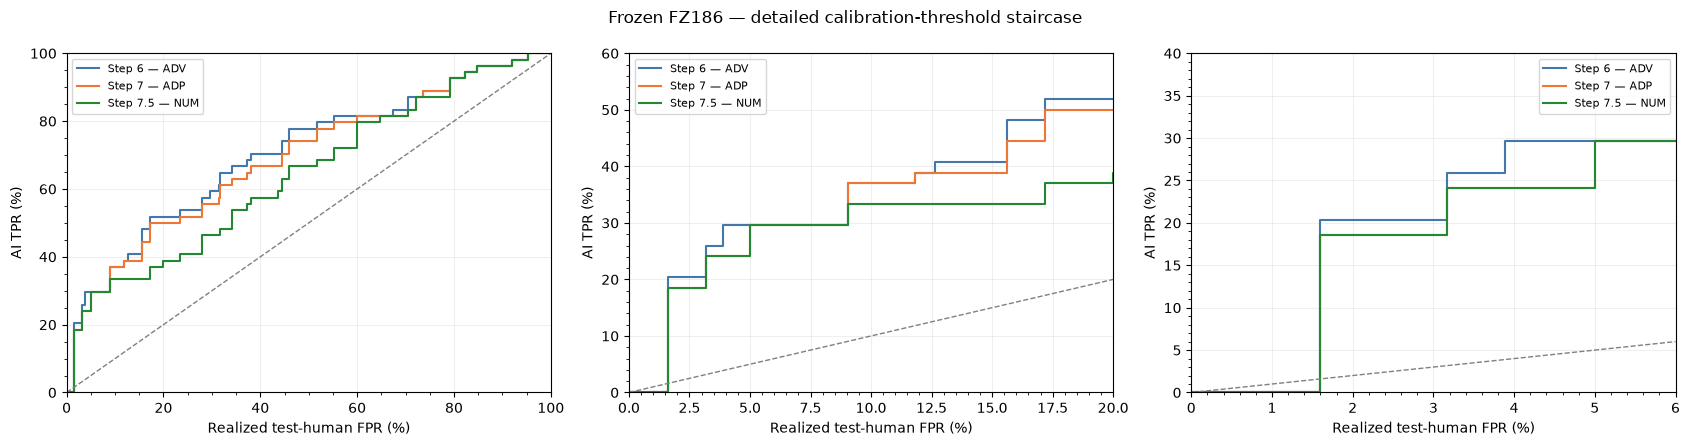

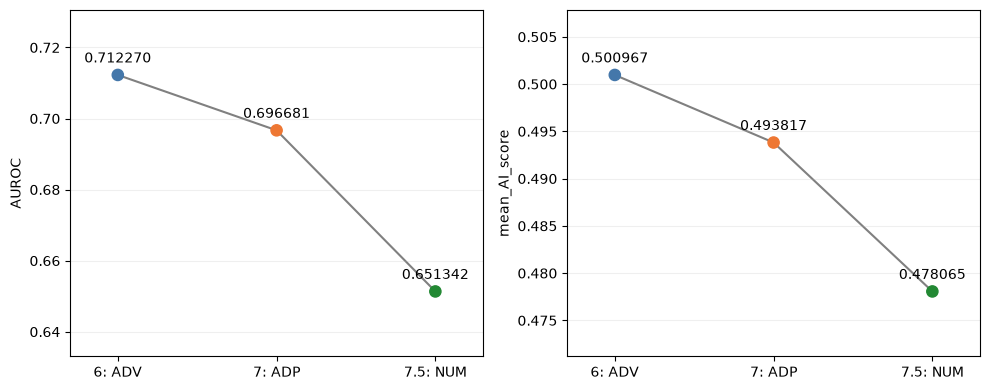

KeyError: "['n_characters'] not in index"

In [16]:
# Step 7.5 completion: long-form years, then three-stage evaluation.
# Run in the current C03d kernel. No likelihood model or detector retraining.
from pathlib import Path
import json, hashlib, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from IPython.display import display

ADV_DIR = Path(ACCEPTED_DIR)
ADP_DIR = Path(adp_dir)
NUM_PILOT_DIR = Path(NUM_OUT)

adv = pd.read_csv(ADV_DIR / "accepted_texts_and_scores.csv", keep_default_na=False)
adp = pd.read_csv(ADP_DIR / "accepted_texts_and_scores.csv", keep_default_na=False)
pilot = pd.read_csv(NUM_PILOT_DIR / "accepted_texts_and_scores.csv", keep_default_na=False)
ids = adv.case_id.astype(str).tolist()

def align(frame):
    assert frame.case_id.is_unique
    assert set(frame.case_id.astype(str)) == set(ids)
    frame = frame.copy()
    frame["case_id"] = frame.case_id.astype(str)
    return frame.set_index("case_id").loc[ids].reset_index()

adv, adp, pilot = map(align, (adv, adp, pilot))
assert len(ids) == 54
assert adv.domain.tolist() == adp.domain.tolist() == pilot.domain.tolist()
assert adv.source_id.tolist() == adp.source_id.tolist() == pilot.source_id.tolist()

# Long cardinal rendering: 2019 -> two thousand nineteen.
small = (
    "zero one two three four five six seven eight nine ten eleven twelve "
    "thirteen fourteen fifteen sixteen seventeen eighteen nineteen"
).split()
tens = "zero ten twenty thirty forty fifty sixty seventy eighty ninety".split()

def long_number(n):
    if n < 20:
        return small[n]
    if n < 100:
        return tens[n // 10] + ("-" + small[n % 10] if n % 10 else "")
    if n < 1000:
        return small[n // 100] + " hundred" + (
            " " + long_number(n % 100) if n % 100 else ""
        )
    return long_number(n // 1000) + " thousand" + (
        " " + long_number(n % 1000) if n % 1000 else ""
    )

# Supported year notation: standalone four-digit years 1000–2999.
# DATE entities identify years; linked range endpoints inherit that evidence.
year_pattern = re.compile(r"(?<![\w])(?:1|2)\d{3}(?![\w])")
range_connector = re.compile(
    r"\s*(?:[-–—]|to|through|until|and)\s*", re.I
)
identifier_words = {"model", "version", "isbn", "id", "page", "section"}

def find_years(text):
    doc = nlp(text)
    candidates = []
    for m in year_pattern.finditer(text):
        a, b = m.span()
        left, right = text[max(0, a-1):a], text[b:b+1]
        # Exclude decimal fragments, formatted quantities, fractions and codes.
        if left in {"/", "_", "$", "£", "€", "+"}:
            continue
        if right in {"/", "_", "%"}:
            continue
        if re.search(r"\d[.,]$", text[:a]) or re.match(r"[.,]\d", text[b:]):
            continue
        span = doc.char_span(a, b, alignment_mode="strict")
        if span is None:
            continue
        previous = doc[span.start-1].lower_ if span.start else ""
        overlaps = [e for e in doc.ents if e.start_char < b and e.end_char > a]
        date = any(e.label_ == "DATE" for e in overlaps)
        blocked = previous in identifier_words or any(
            e.label_ not in {"DATE", "CARDINAL"} for e in overlaps
        )
        candidates.append({
            "a": a, "b": b, "year": int(m.group()),
            "recognized": date and not blocked,
            "blocked": blocked,
            "reason": "DATE entity" if date and not blocked else "unclassified",
        })

    # Handles "from 2016 to 2019" even if only one endpoint is tagged DATE.
    for x, y in zip(candidates, candidates[1:]):
        if (
            not x["blocked"] and not y["blocked"]
            and range_connector.fullmatch(text[x["b"]:y["a"]])
            and (x["recognized"] or y["recognized"])
        ):
            for item in (x, y):
                if not item["recognized"]:
                    item["recognized"] = True
                    item["reason"] = "range linked to DATE year"
    return candidates

year_rows, unresolved_rows, final_texts = [], [], []
for row in pilot.itertuples():
    text = str(row.text)
    found = find_years(text)
    edits = [x for x in found if x["recognized"]]
    for item in found:
        record = {
            "case_id": row.case_id, "domain": row.domain,
            "year": item["year"], "reason": item["reason"],
            "context": text[max(0, item["a"]-65):item["b"]+65],
        }
        if item["recognized"]:
            replacement = long_number(item["year"])
            year_rows.append({**record, "replacement": replacement})
        else:
            unresolved_rows.append(record)

    # Replace every recognized occurrence; no per-edit contribution selection.
    edited = text
    for item in sorted(edits, key=lambda x: x["a"], reverse=True):
        assert text[item["a"]:item["b"]] == str(item["year"])
        edited = (
            edited[:item["a"]] + long_number(item["year"])
            + edited[item["b"]:]
        )
    final_texts.append(edited)

def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

execution_source = get_ipython().history_manager.input_hist_raw[-1]
year_contract = {
    "version": "step75_all_identified_long_years_v1",
    "input_hashes": {
        str(p): digest(p) for p in [
            ADV_DIR / "accepted_texts_and_scores.csv",
            ADP_DIR / "accepted_texts_and_scores.csv",
            NUM_PILOT_DIR / "accepted_texts_and_scores.csv",
            Path(RUN_DIR) / "FZ186.pkl",
        ]
    },
    "code_sha256": hashlib.sha256(execution_source.encode()).hexdigest(),
    "policy": "all recognized years; long cardinal form; no score-based acceptance",
    "prior_NUM_conversions": "retained",
}
run = hashlib.sha256(json.dumps(year_contract, sort_keys=True).encode()).hexdigest()[:12]
NUM_FINAL_DIR = Path(ROOT) / "results/causal/C03d_NUM_final_years" / run
NUM_FINAL_DIR.mkdir(parents=True, exist_ok=True)
(NUM_FINAL_DIR / "contract.json").write_text(json.dumps(year_contract, indent=2))
FIG = Path(ROOT) / "figures"
FIG.mkdir(exist_ok=True)

pd.DataFrame(year_rows).to_csv(NUM_FINAL_DIR / "year_conversions.csv", index=False)
pd.DataFrame(unresolved_rows).to_csv(
    NUM_FINAL_DIR / "unclassified_four_digit_numbers.csv", index=False
)
print(f"Converted {len(year_rows)} year occurrences across "
      f"{len(set(r['case_id'] for r in year_rows))} documents.")
display(pd.DataFrame(year_rows))
if unresolved_rows:
    print("Unclassified four-digit numbers left unchanged:")
    display(pd.DataFrame(unresolved_rows))

# Extract only final texts; per-document checkpoints make this resumable.
vector_dir = NUM_FINAL_DIR / "vectors"
vector_dir.mkdir(exist_ok=True)
xs, cs = [], []
for i, text in enumerate(final_texts):
    key = hashlib.sha256(text.encode()).hexdigest()
    path = vector_dir / f"{key}.npz"
    if path.exists():
        with np.load(path, allow_pickle=False) as z:
            x, c = z["x"], z["c"]
    else:
        frame = full_frame([text])
        x, c = frame.iloc[0].to_numpy(), contributions(frame)[0]
        temp = path.with_suffix(".tmp")
        with temp.open("wb") as f:
            np.savez_compressed(f, x=x, c=c)
        temp.replace(path)
    xs.append(x)
    cs.append(c)
    if (i+1) % 10 == 0 or i+1 == len(final_texts):
        print(f"Final NUM features: {i+1}/{len(final_texts)}", flush=True)

final = pilot.copy()
final["text"] = final_texts
final["year_conversion_applied"] = final.text.ne(pilot.text)
final["post_NUM_AI_score"] = detector.predict_proba(
    pd.DataFrame(xs, columns=COLS)
)[:, 1]
final.to_csv(NUM_FINAL_DIR / "accepted_texts_and_scores.csv", index=False)

# Load frozen human scores; do not rescore humans or recalibrate the detector.
human_cache = ADV_DIR.parent.parent / "frozen_human_scores"

def frozen_humans(split):
    manifest = pd.read_csv(Path(RUN_DIR) / f"human_{split}_manifest.csv")
    matches = []
    for p in sorted(human_cache.glob(f"{split}_*.csv")):
        z = pd.read_csv(p)
        if not {"source_id", "score", "weight"} <= set(z.columns):
            continue
        if (
            z.source_id.astype(str).tolist()
            == manifest.source_id.astype(str).tolist()
            and np.allclose(z.weight, manifest.weight, atol=1e-12, rtol=0)
        ):
            matches.append(z)
    assert matches, f"No matching {split} score cache in {human_cache}"
    for z in matches[1:]:
        np.testing.assert_allclose(z.score, matches[0].score, atol=1e-12, rtol=0)
    assert np.isclose(matches[0].weight.sum(), 1)
    return matches[0]

cal = frozen_humans("calibration")
human = frozen_humans("test")
stage_scores = {
    "Step 6 — ADV": adv.after_AI_score.to_numpy(),
    "Step 7 — ADP": adp.post_ADP_AI_score.to_numpy(),
    "Step 7.5 — NUM": final.post_NUM_AI_score.to_numpy(),
}
colors = ["#4477AA", "#EE7733", "#228833"]
summary = []
for stage, scores in stage_scores.items():
    assert np.isfinite(scores).all()
    y = np.r_[np.zeros(len(human)), np.ones(len(scores))]
    s = np.r_[human.score, scores]
    w = np.r_[human.weight, np.ones(len(scores))/len(scores)]
    summary.append({
        "stage": stage,
        "AUROC": roc_auc_score(y, s, sample_weight=w),
        "mean_AI_score": scores.mean(),
        "n_AI": len(scores),
    })
summary = pd.DataFrame(summary)
summary.to_csv(NUM_FINAL_DIR / "stage_summary.csv", index=False)
display(summary)

def save_plot(fig, stem):
    fig.tight_layout()
    for folder in (NUM_FINAL_DIR, FIG):
        for ext in ("pdf", "png"):
            fig.savefig(folder / f"{stem}.{ext}", dpi=300, bbox_inches="tight")
    plt.show()

# Detailed staircase: every distinct validation-human score.
thresholds = np.r_[np.inf, np.unique(cal.score)[::-1], -np.inf]
stairs = pd.DataFrame({
    "threshold": thresholds,
    "calibration_FPR": [
        cal.loc[cal.score > t, "weight"].sum() for t in thresholds
    ],
    "test_FPR": [
        human.loc[human.score > t, "weight"].sum() for t in thresholds
    ],
})
for stage, scores in stage_scores.items():
    stairs[stage] = [(scores > t).mean() for t in thresholds]
stairs.to_csv(NUM_FINAL_DIR / "detailed_TPR_staircase.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, xmax, ymax in zip(axes, [1, .2, .06], [1, .6, .4]):
    for (stage, scores), color in zip(stage_scores.items(), colors):
        ax.step(100*stairs.test_FPR, 100*stairs[stage],
                where="post", label=stage, color=color)
    ax.plot([0, 100*xmax], [0, 100*xmax], "--", color="gray", lw=1)
    ax.set(xlim=(0, 100*xmax), ylim=(0, 100*ymax),
           xlabel="Realized test-human FPR (%)", ylabel="AI TPR (%)")
    ax.minorticks_on()
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
fig.suptitle("Frozen FZ186 — detailed calibration-threshold staircase")
save_plot(fig, "C03d_steps6_7_75_TPR_staircase")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric in zip(axes, ["AUROC", "mean_AI_score"]):
    ax.plot(range(3), summary[metric], color="gray", zorder=1)
    ax.scatter(range(3), summary[metric], c=colors, s=65, zorder=2)
    for i, value in enumerate(summary[metric]):
        ax.annotate(f"{value:.6f}", (i, value), xytext=(0, 9),
                    textcoords="offset points", ha="center")
    ax.set_xticks(range(3), ["6: ADV", "7: ADP", "7.5: NUM"])
    ax.set_ylabel(metric)
    ax.margins(x=.15, y=.3)
    ax.grid(axis="y", alpha=.2)
save_plot(fig, "C03d_steps6_7_75_AUROC_mean_score")

# Fixed per-case human reference, recovered from original C03 artifacts.
original_c = pd.read_csv(
    Path(RUN_DIR) / "FZ186_case_contributions.csv", index_col=0
).loc[ids, COLS].to_numpy()
original_g = pd.read_csv(
    Path(RUN_DIR) / "FZ186_case_contribution_gaps.csv", index_col=0
).loc[ids, COLS].to_numpy()
final_g = np.asarray(cs) - (original_c - original_g)

def read_gaps(directory):
    return pd.read_csv(
        directory / "case_contribution_gaps.csv", index_col=0
    ).loc[ids, COLS].to_numpy()

adv_g = read_gaps(ADV_DIR)
adp_g = read_gaps(ADP_DIR)
pd.DataFrame(final_g, index=ids, columns=COLS).rename_axis("case_id").to_csv(
    NUM_FINAL_DIR / "case_contribution_gaps.csv"
)

# Descriptive genre-stratified bootstrap; human references stay fixed.
rng = np.random.default_rng(20260910)
B = 3000
boot = np.zeros((B, len(COLS)))
genres = final.domain.to_numpy()
for genre in sorted(set(genres)):
    ix = np.flatnonzero(genres == genre)
    draws = rng.choice(ix, size=(B, len(ix)), replace=True)
    boot += len(ix)/len(ids) * final_g[draws].mean(1)
lo, hi = np.quantile(boot, [.025, .975], axis=0)

rank = pd.DataFrame({
    "feature": COLS,
    "ADV_gap": adv_g.mean(0),
    "ADP_gap": adp_g.mean(0),
    "NUM_gap": final_g.mean(0),
    "ci_low": lo, "ci_high": hi,
    "NUM_stage_change": (final_g-adp_g).mean(0),
}).sort_values("NUM_gap", ascending=False)
rank.to_csv(NUM_FINAL_DIR / "remaining_contributions.csv", index=False)
display(rank.head(30))

top = rank.head(30).iloc[::-1]
y = np.arange(len(top))
fig, ax = plt.subplots(figsize=(11, 10))
ax.hlines(y, top.ci_low, top.ci_high, color="gray", alpha=.6)
for column, stage, color in zip(
    ["ADV_gap", "ADP_gap", "NUM_gap"], stage_scores, colors
):
    ax.scatter(top[column], y, color=color, label=stage, s=30)
ax.set_yticks(y, top.feature)
ax.axvline(0, color="gray", lw=1)
ax.set_xlabel("Mean contribution minus fixed same-genre human reference")
ax.set_title("Top 30 remaining contributions after step 7.5")
ax.legend()
save_plot(fig, "C03d_steps6_7_75_remaining_contributions")

print("Final NUM output:", NUM_FINAL_DIR)
print(
    "Step 7.5 includes the earlier accepted cardinal conversions plus "
    "all identified long-form year conversions. Year edits were not "
    "selected for score improvement, so their measured effect may vary."
)

,feature,ADV_gap,ADP_gap,NUM_gap,ci_low,ci_high,NUM_stage_change
12,share_long_words,0.002948,0.002838,0.003026,0.001894,0.004153,0.000187
120,pos_ADJ_sentence_std,0.003213,0.003045,0.002849,0.000930,0.004820,-0.000196
23,share_unique_words,0.002692,0.002660,0.002793,0.000195,0.006015,0.000134
163,pos_PROPN_sentence_mean,0.001967,0.002083,0.002720,0.001026,0.004407,0.000637
134,pos_CCONJ_token_share,0.003025,0.002832,0.002607,0.001468,0.003703,-0.000224
129,pos_ADV_sentence_max,0.002536,0.002312,0.002304,0.000763,0.003891,-0.000008
125,pos_ADP_sentence_max,0.004079,0.002337,0.002252,0.000978,0.003491,-0.000084
14,coleman_liau_index,0.001923,0.001905,0.002153,0.001435,0.002889,0.000247
126,pos_ADV_token_share,0.001869,0.001877,0.002004,0.000866,0.003154,0.000127
26,share_google_top10000,0.002210,0.002021,0.001936,0.000004,0.003821,-0.000085


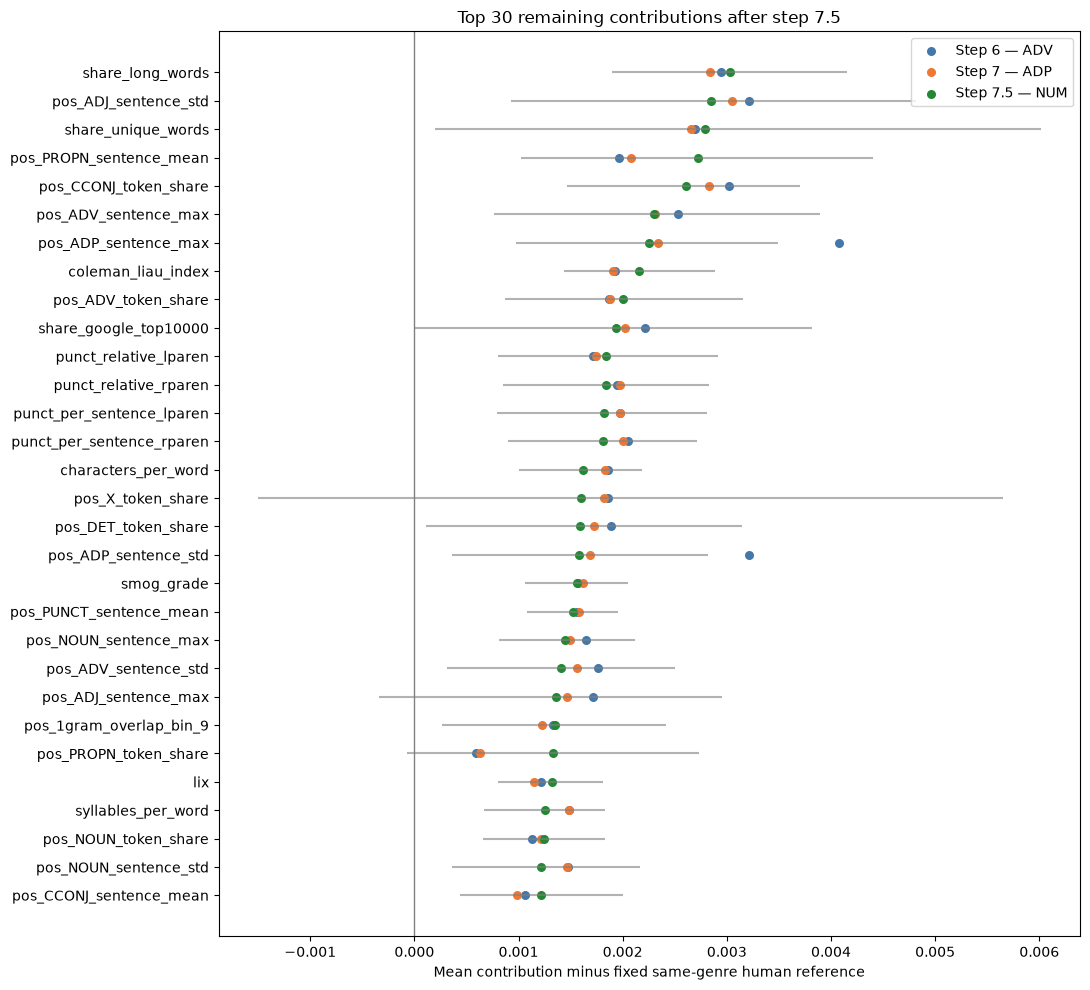

Contribution table and PDF/PNG graph saved. No rescoring performed.


In [17]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Always select the named case-ID column, regardless of CSV column order.
plot_ids = final.case_id.astype(str).tolist()

def load_contribution_frame(path):
    frame = pd.read_csv(path)
    assert "case_id" in frame.columns, f"Missing case_id column: {path}"
    frame["case_id"] = frame["case_id"].astype(str)
    assert frame.case_id.is_unique, f"Duplicate case IDs: {path}"
    missing = set(COLS) - set(frame.columns)
    assert not missing, f"Missing features in {path}: {sorted(missing)}"
    return frame.set_index("case_id").loc[plot_ids, COLS].to_numpy(float)

original_c = load_contribution_frame(
    Path(RUN_DIR) / "FZ186_case_contributions.csv"
)
original_g = load_contribution_frame(
    Path(RUN_DIR) / "FZ186_case_contribution_gaps.csv"
)
adv_g = load_contribution_frame(
    Path(ADV_DIR) / "case_contribution_gaps.csv"
)
adp_g = load_contribution_frame(
    Path(ADP_DIR) / "case_contribution_gaps.csv"
)

# cs contains the final contributions computed before the plotting error.
final_c = np.asarray(cs, dtype=float)
assert final_c.shape == original_c.shape == (len(plot_ids), len(COLS))
assert np.isfinite(final_c).all()
final_g = final_c - (original_c - original_g)

pd.DataFrame(
    final_g, index=pd.Index(plot_ids, name="case_id"), columns=COLS
).to_csv(Path(NUM_FINAL_DIR) / "case_contribution_gaps.csv")

# Descriptive bootstrap with fixed human references.
rng = np.random.default_rng(20260910)
B = 3000
boot = np.zeros((B, len(COLS)))
genres = final.domain.astype(str).to_numpy()

for genre in sorted(set(genres)):
    ix = np.flatnonzero(genres == genre)
    draws = rng.choice(ix, size=(B, len(ix)), replace=True)
    boot += len(ix) / len(plot_ids) * final_g[draws].mean(axis=1)

lo, hi = np.quantile(boot, [.025, .975], axis=0)
rank = pd.DataFrame({
    "feature": COLS,
    "ADV_gap": adv_g.mean(axis=0),
    "ADP_gap": adp_g.mean(axis=0),
    "NUM_gap": final_g.mean(axis=0),
    "ci_low": lo,
    "ci_high": hi,
    "NUM_stage_change": (final_g - adp_g).mean(axis=0),
}).sort_values("NUM_gap", ascending=False)

rank.to_csv(
    Path(NUM_FINAL_DIR) / "remaining_contributions.csv", index=False
)
display(rank.head(30))

top = rank.head(30).iloc[::-1]
y = np.arange(len(top))
fig, ax = plt.subplots(figsize=(11, 10))
ax.hlines(y, top.ci_low, top.ci_high, color="gray", alpha=.6)

for column, label, color in [
    ("ADV_gap", "Step 6 — ADV", "#4477AA"),
    ("ADP_gap", "Step 7 — ADP", "#EE7733"),
    ("NUM_gap", "Step 7.5 — NUM", "#228833"),
]:
    ax.scatter(top[column], y, color=color, label=label, s=30)

ax.set_yticks(y, top.feature)
ax.axvline(0, color="gray", lw=1)
ax.set_xlabel("Mean contribution minus fixed same-genre human reference")
ax.set_title("Top 30 remaining contributions after step 7.5")
ax.legend()
fig.tight_layout()

for folder in (Path(NUM_FINAL_DIR), Path(ROOT) / "figures"):
    folder.mkdir(parents=True, exist_ok=True)
    for ext in ("pdf", "png"):
        fig.savefig(
            folder / f"C03d_steps6_7_75_remaining_contributions.{ext}",
            dpi=300, bbox_inches="tight",
        )
plt.show()

print("Contribution table and PDF/PNG graph saved. No rescoring performed.")

In [6]:
from pathlib import Path
import json
import re

root = Path(ROOT)
readme = root / "README.md"
assert readme.is_file()
NUM_FINAL_DIR = Path(ROOT) / "results/causal/C03d_NUM_final_years" / "3e7f9d9e6268"
final_dir = Path(NUM_FINAL_DIR)
assert (final_dir / "accepted_texts_and_scores.csv").is_file()
assert (final_dir / "remaining_contributions.csv").is_file()

def relative_path(path):
    path = Path(path).resolve()
    try:
        return path.relative_to(root.resolve()).as_posix()
    except ValueError:
        return str(path)
ADP_DIR = Path(ROOT) / "results/causal/C03d_ADP_boost_compensate"/"1d921b4b832b"
NUM_PILOT_DIR = Path(ROOT) / "results/causal/C03d_ADP_boost_compensate"/"7ceb612bac6d"
final_rel = relative_path(final_dir)
adp_rel = relative_path(ADP_DIR)
pilot_rel = relative_path(NUM_PILOT_DIR)

start = "<!-- CURRENT_C03D_HANDOFF_START -->"
end = "<!-- CURRENT_C03D_HANDOFF_END -->"

handoff = f"""
{start}
## Current handoff: C03d complete through step 7.5; paused

**This section supersedes older workflow and handoff notes below.**
C03c contains completed steps 5–6. C03d contains step 7 (ADP),
step 7.5 (NUM), and their evaluation. The next intervention and notebook
name have not been selected.

### Resume from the final NUM output

- Accepted next-stage input: `{final_rel}/accepted_texts_and_scores.csv`.
- Final score column: `post_NUM_AI_score`. Earlier score columns are
  historical stage scores, not scores of the final text.
- Final NUM directory: `{final_rel}`.
- Accepted ADP directory: `{adp_rel}`.
- Initial NUM pilot directory: `{pilot_rel}`.
- Load saved artifacts in a fresh kernel. Do not depend on live variables
  or rerun generation, candidate search, or fitting merely to resume.
- Retain all 54 development sources, the frozen full FZ186 detector,
  feature order, human reference manifests, and human weights.
  FZ182 remains a diagnostic ablation only.
- Preserve contracts, conversion logs, per-case checkpoints, cached
  vectors, contribution tables, and numerical plotting data.
- Later C03d cells were supplied in chat. Save the completed local
  notebook with those cells and outputs; do not assume the GitHub copy
  contains the final NUM or plotting fixes.

### Accepted intervention policies

**Step 7 — ADP:** retain the original −1.0 nats/token broad and local
likelihood floors. The proposed −1.5 experiment was abandoned.
Freeze the ceiling of the same-genre human median sentence maximum as
the threshold. Protect sentences already at or above it. Search for
a boost in a below-threshold sentence, then attempt ADP reductions in
below-threshold sentences to restore the incoming token share.
The pilot boosts at most one new high-count sentence per document.
Final acceptance requires ADP-block improvement, no increase in combined
non-ADP contribution, a non-decreasing maximum, and increased SD.
Compensation is best-effort rather than exact.

The run accepted 15/54 documents; 25 had no reachable boost within the
recorded bounds and 14 had no final acceptance. Ten accepted documents
received compensation edits. Individual collateral features can increase
despite the combined contribution constraint.

**Step 7.5 — NUM:** retain the three accepted conversions from the initial
bidirectional cardinal-integer pilot, then apply long-form conversion to
all years recognized by the implemented rules, including linked range
endpoints. Use “two thousand nineteen,” not “twenty nineteen.”
The final year pass is not selected by likelihood or detector improvement.
Numeric values and surrounding text are preserved by replacement;
POS tags and collateral features can change.

Fractions were investigated but not treated. In the tested examples,
spelling out fractions left NUM count unchanged and lowered token share.
The year recognizer left an unclassified `2003` in `gate_0051` unchanged;
see the saved unclassified-number audit. Do not describe every possible
year as converted. NUM work is paused as complete at this tested scope.

### Evaluation checkpoint

| Stage | AUROC | Mean AI score |
|---|---:|---:|
| Step 6 — ADV | 0.712270 | 0.500967 |
| Step 7 — ADP | 0.696681 | 0.493817 |
| Step 7.5 — NUM | 0.651342 | 0.478065 |

These are frozen-detector, development-cohort results on the same
54 sources and fixed genre-weighted test humans. A mean score below .5
does not establish indistinguishability. Detailed numerical reports and
scientific interpretation belong in `paper/main.tex`; this README update
does not update the manuscript.

The detailed TPR staircase sweeps all distinct calibration-human score
thresholds, uses strict `score > threshold`, and plots realized test-human
FPR. It is a calibration-threshold sweep, not the full empirical ROC.
AUROC is computed separately from the full weighted score ranking.

Remaining contributions use fixed same-genre human references.
The top residuals now include `share_long_words`, `pos_ADJ_sentence_std`,
`share_unique_words`, `pos_PROPN_sentence_mean`, and
`pos_CCONJ_token_share`. NUM is absent from the displayed top 30.
ADP sentence maximum and SD remain positive residuals.
No next target has yet been chosen. Bootstrap intervals are descriptive
after selection, with human references fixed.

### Saved figures and CSV-loading fix

Final figures are exported as both PDF and PNG under `reproduction/figures/`
and the final NUM run directory, with stems:

- `C03d_steps6_7_75_TPR_staircase`
- `C03d_steps6_7_75_AUROC_mean_score`
- `C03d_steps6_7_75_remaining_contributions`

Keep matching figure references in `paper/main.tex` when integrating
steps 7–7.5 into the manuscript. Export-only work must reuse saved scores.

**CSV fix:** read original C03 contribution files with
`pd.read_csv(path).set_index("case_id")`, not `index_col=0`.
Their first column can be `n_characters`; treating it as the index removes
a required feature. The contribution plotting error was repaired without
rescoring, and the final contribution table and figures were saved.

### Collaboration preference

Do not push changes to GitHub unless explicitly requested.
For a one-cell change, paste the cell in chat. For a notebook or file
update, provide the file directly.
{end}
""".strip()

text = readme.read_text()
# Replace this managed handoff on reruns; retain older project history.
text = re.sub(
    re.escape(start) + r".*?" + re.escape(end) + r"\n*",
    "",
    text,
    flags=re.S,
)

# Label a previous "Current workflow" section as historical.
text = re.sub(
    r"^## Current workflow:(.*)$",
    r"## Previous workflow snapshot:\1",
    text,
    flags=re.M,
)

lines = text.splitlines(keepends=True)
assert lines and lines[0].startswith("# "), "Expected README title."
updated = lines[0].rstrip() + "\n\n" + handoff + "\n\n" + "".join(lines[1:]).lstrip()

# Preserve a one-time backup of the README before this handoff.
backup = readme.with_name("README.before_C03d_step75.md")
if not backup.exists():
    backup.write_text(readme.read_text())

temp = readme.with_suffix(".md.tmp")
temp.write_text(updated)
temp.replace(readme)

print("Updated:", readme)
print("Next-stage input:", final_dir / "accepted_texts_and_scores.csv")
print("Local update only; no GitHub push.")

Updated: ../README.md
Next-stage input: ../results/causal/C03d_NUM_final_years/3e7f9d9e6268/accepted_texts_and_scores.csv
Local update only; no GitHub push.
